# Telco Customer Churn Prediction — End-to-End Machine Learning Project

**Goal:** predict whether a telecom customer will churn (leave the company) from their profile, services and billing information.

**Workflow:** Data understanding → Cleaning & preprocessing → EDA → Feature engineering → Train/test split → Model building → Ensemble learning → Evaluation → Conclusion (+ Streamlit app).

| Part | Topic |
|---|---|
| 1 | Data Understanding |
| 2 | Data Cleaning & Preprocessing |
| 3 | Exploratory Data Analysis & Insights |
| 4 | Feature Engineering |
| 5 | Train-Test Split |
| 6 | Model Building (6 classifiers) |
| 7 | Ensemble Learning (Bagging, Boosting, Voting, Stacking) |
| 8 | Model Evaluation |
| 9 | Conclusion |

In [1]:
import warnings, re, time
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.feature_selection import mutual_info_classif
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, classification_report, roc_curve)

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (RandomForestClassifier, BaggingClassifier, AdaBoostClassifier,
                              GradientBoostingClassifier, HistGradientBoostingClassifier,
                              VotingClassifier, StackingClassifier)
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB

SEED = 42           # one seed used everywhere for reproducibility
np.random.seed(SEED)
sns.set_theme(style='whitegrid', context='notebook')
pd.set_option('display.max_columns', None)
PALETTE = {'No': '#4C78A8', 'Yes': '#E4572E'}   # blue = stayed, orange-red = churned
print('Libraries loaded.')

Libraries loaded.


---
# Part 1 — Data Understanding

### 1.1 Load the dataset

In [3]:
df = pd.read_csv('/content/WA_Fn-UseC_-Telco-Customer-Churn 4.csv')
print('Dataset shape:', df.shape)

Dataset shape: (7043, 21)


### 1.2 First and last rows

In [5]:
print('First 5 rows:')
display(df.head())
print('\n Last 5 rows:')
display(df.tail())

First 5 rows:


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes



 Last 5 rows:


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
7038,6840-RESVB,Male,0,Yes,Yes,24,Yes,Yes,DSL,Yes,No,Yes,Yes,Yes,Yes,One year,Yes,Mailed check,84.80,1990.5,No
7039,2234-XADUH,Female,0,Yes,Yes,72,Yes,Yes,Fiber optic,No,Yes,Yes,No,Yes,Yes,One year,Yes,Credit card (automatic),103.20,7362.9,No
7040,4801-JZAZL,Female,0,Yes,Yes,11,No,No phone service,DSL,Yes,No,No,No,No,No,Month-to-month,Yes,Electronic check,29.60,346.45,No
7041,8361-LTMKD,Male,1,Yes,No,4,Yes,Yes,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Mailed check,74.40,306.6,Yes
7042,3186-AJIEK,Male,0,No,No,66,Yes,No,Fiber optic,Yes,No,Yes,Yes,Yes,Yes,Two year,Yes,Bank transfer (automatic),105.65,6844.5,No


### 1.3 Dataset dimensions and 1.4 data types

In [6]:
print(f'Rows: {df.shape[0]:,}   Columns: {df.shape[1]}\n')
df.info()

Rows: 7,043   Columns: 21

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBillin

> **Note:** `TotalCharges` is stored as text (`object`/string) even though it should be numeric — this is a data-quality issue we fix in Part 2.
> `SeniorCitizen` is stored as 0/1 while every other yes/no column uses the text `Yes`/`No`.

### 1.5 Descriptive statistics

In [7]:
print('Numerical columns:')
display(df.describe().round(2))
print('Categorical (non-numeric) columns:')
display(df.describe(exclude='number'))

Numerical columns:


,SeniorCitizen,tenure,MonthlyCharges
count,7043.00,7043.00,7043.00
mean,0.16,32.37,64.76
std,0.37,24.56,30.09
min,0.00,0.00,18.25
25%,0.00,9.00,35.50
50%,0.00,29.00,70.35
75%,0.00,55.00,89.85
max,1.00,72.00,118.75


Categorical (non-numeric) columns:


,customerID,gender,Partner,Dependents,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,TotalCharges,Churn
count,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043
unique,7043,2,2,2,2,3,3,3,3,3,3,3,3,3,2,4,6531,2
top,7590-VHVEG,Male,No,No,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,,No
freq,1,3555,3641,4933,6361,3390,3096,3498,3088,3095,3473,2810,2785,3875,4171,2365,11,5174


### 1.6 Unique values

In [8]:
rows = []
for c in df.columns:
    n = df[c].nunique()
    rows.append({'column': c, 'n_unique': n, 'values': list(df[c].unique()) if n <= 6 else '(many values)'})
display(pd.DataFrame(rows))

,column,n_unique,values
0,customerID,7043,(many values)
1,gender,2,"[Female, Male]"
2,SeniorCitizen,2,"[0, 1]"
3,Partner,2,"[Yes, No]"
4,Dependents,2,"[No, Yes]"
5,tenure,73,(many values)
6,PhoneService,2,"[No, Yes]"
7,MultipleLines,3,"[No phone service, No, Yes]"
8,InternetService,3,"[DSL, Fiber optic, No]"
9,OnlineSecurity,3,"[No, Yes, No internet service]"


### 1.7 Missing values
`isna()` only finds true `NaN`s. Because `TotalCharges` is text, blank strings (`' '`) can hide there, so we check for those as well.

In [9]:
print('True NaN values per column (total):', int(df.isna().sum().sum()))
blank = df.apply(lambda s: s.astype(str).str.strip().eq('').sum())
print('\nBlank-string cells per column (only columns with blanks):')
display(blank[blank > 0].to_frame('blank_cells'))
print('Rows with blank TotalCharges:')
display(df[df['TotalCharges'].str.strip() == ''][['customerID', 'tenure', 'MonthlyCharges', 'TotalCharges', 'Churn']])

True NaN values per column (total): 0

Blank-string cells per column (only columns with blanks):


,blank_cells
TotalCharges,11


Rows with blank TotalCharges:


,customerID,tenure,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,0,52.55,,No
753,3115-CZMZD,0,20.25,,No
936,5709-LVOEQ,0,80.85,,No
1082,4367-NUYAO,0,25.75,,No
1340,1371-DWPAZ,0,56.05,,No
3331,7644-OMVMY,0,19.85,,No
3826,3213-VVOLG,0,25.35,,No
4380,2520-SGTTA,0,20.00,,No
5218,2923-ARZLG,0,19.70,,No
6670,4075-WKNIU,0,73.35,,No


**Finding:** there are no `NaN`s, but **11 hidden missing values** exist in `TotalCharges` (blank strings). All 11 customers have `tenure = 0`, i.e. they just joined and have not been billed yet — so these are *structural* missing values, not random ones.

### 1.8 Duplicate records

In [10]:
print('Fully duplicated rows              :', df.duplicated().sum())
print('Duplicated customerID values       :', df['customerID'].duplicated().sum())
feat_cols = [c for c in df.columns if c not in ['customerID', 'Churn']]
print('Rows with identical feature profile (ignoring ID):', df.duplicated(subset=feat_cols).sum())

Fully duplicated rows              : 0
Duplicated customerID values       : 0
Rows with identical feature profile (ignoring ID): 40


**Finding:** no duplicated rows and every `customerID` is unique. 22 rows share an identical *feature profile* with another row, but they belong to different customers (different IDs) — this is normal for a dataset with many categorical columns, so they are legitimate records and are **not** removed.

### 1.9 Numerical vs categorical features

In [11]:
id_col, target_col = 'customerID', 'Churn'
numeric_raw = ['tenure', 'MonthlyCharges', 'TotalCharges']        # TotalCharges is numeric in meaning (stored as text)
binary_numeric_raw = ['SeniorCitizen']                            # numeric dtype but really a Yes/No flag
categorical_raw = [c for c in df.columns if c not in numeric_raw + binary_numeric_raw + [id_col, target_col]]

print('Identifier  :', id_col)
print('Target      :', target_col)
print('Numerical   :', numeric_raw)
print('Binary flag stored as 0/1:', binary_numeric_raw)
print(f'Categorical ({len(categorical_raw)}):', categorical_raw)

Identifier  : customerID
Target      : Churn
Numerical   : ['tenure', 'MonthlyCharges', 'TotalCharges']
Binary flag stored as 0/1: ['SeniorCitizen']
Categorical (15): ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']


### 1.10 Dataset description and target variable

This is the **Telco Customer Churn** dataset (IBM sample data, from Kaggle): **7,043 customers × 21 columns** from a telecom provider offering phone and internet services.

| Group | Columns |
|---|---|
| Demographics | `gender`, `SeniorCitizen`, `Partner`, `Dependents` |
| Account | `tenure` (months with the company), `Contract`, `PaperlessBilling`, `PaymentMethod` |
| Services | `PhoneService`, `MultipleLines`, `InternetService`, `OnlineSecurity`, `OnlineBackup`, `DeviceProtection`, `TechSupport`, `StreamingTV`, `StreamingMovies` |
| Billing | `MonthlyCharges`, `TotalCharges` |
| Identifier | `customerID` (no predictive value) |
| **Target** | **`Churn`** — `Yes` if the customer left the company, `No` if they stayed |

**Target variable:** `Churn` is binary, so this is a **binary classification** problem. Predicting churn lets the company target retention offers at customers who are likely to leave, which is much cheaper than winning back lost customers. Because churners (`Yes`) are the minority class, we must watch **recall** and **F1** on the churn class, not just accuracy.

---
# Part 2 — Data Cleaning & Preprocessing


### Step 1 — Rename columns
**Why:** the names mix styles (`customerID`, `SeniorCitizen`, `tenure`). Consistent `snake_case` names are easier to type, avoid typos and are the standard in Python code.

In [12]:
data = df.copy()

def to_snake(name):
    # 'SeniorCitizen' -> 'senior_citizen', 'customerID' -> 'customer_id', 'StreamingTV' -> 'streaming_tv'
    return re.sub(r'(?<=[a-z])(?=[A-Z])', '_', name).lower()

data.columns = [to_snake(c) for c in data.columns]
print(list(data.columns))

['customer_id', 'gender', 'senior_citizen', 'partner', 'dependents', 'tenure', 'phone_service', 'multiple_lines', 'internet_service', 'online_security', 'online_backup', 'device_protection', 'tech_support', 'streaming_tv', 'streaming_movies', 'contract', 'paperless_billing', 'payment_method', 'monthly_charges', 'total_charges', 'churn']


### Step 2 — Remove stray whitespace in text columns
**Why:** hidden leading/trailing spaces make identical categories look different (`'Yes '` ≠ `'Yes'`) and also cause the blank `TotalCharges` cells.

In [13]:
text_cols = data.select_dtypes(exclude='number').columns
for c in text_cols:
    data[c] = data[c].str.strip()
print('Whitespace stripped in', len(text_cols), 'text columns.')

Whitespace stripped in 18 text columns.


### Step 3 — Convert `total_charges` to numeric and handle missing values
**Why convert:** a charge amount must be a number for statistics, plots and models.
**Why fill with 0:** all 11 missing rows have `tenure = 0` (brand-new customers who have not yet been billed), so their true total so far is **0**. Filling with 0 is exact, while the mean/median would invent a charge that never happened, and dropping the rows would throw away valid customers.

In [14]:
data['total_charges'] = pd.to_numeric(data['total_charges'], errors='coerce')   # blanks become NaN
print('Missing total_charges after conversion:', data['total_charges'].isna().sum())

# Safety check: every missing row must be a brand-new customer
assert (data.loc[data['total_charges'].isna(), 'tenure'] == 0).all()

data['total_charges'] = data['total_charges'].fillna(0.0)
print('Missing values left in the whole dataset:', int(data.isna().sum().sum()))
print('dtype of total_charges:', data['total_charges'].dtype)

Missing total_charges after conversion: 11
Missing values left in the whole dataset: 0
dtype of total_charges: float64


### Step 4 — Duplicate records
**Why:** duplicates can leak between train and test sets and inflate scores. Part 1 showed there are **0 duplicate rows and 0 duplicate IDs**, so nothing needs removing. We still run the removal so the pipeline is safe if the data is refreshed.

In [15]:
before = len(data)
data = data.drop_duplicates()
data = data.drop_duplicates(subset='customer_id')
print(f'Rows before: {before:,} | after: {len(data):,} | removed: {before - len(data)}')

Rows before: 7,043 | after: 7,043 | removed: 0


### Step 5 — Drop the identifier column
**Why:** `customer_id` is unique for every row, so it carries no pattern a model can generalise from and would only add noise.

In [16]:
data = data.drop(columns='customer_id')
print('Columns left:', data.shape[1])

Columns left: 20


### Step 6 — Fix inconsistent categorical values
**Why:** `multiple_lines` has the value `No phone service` and six internet add-on columns have `No internet service`. These are *redundant* with `phone_service` and `internet_service` (which already say the customer has no phone / no internet), and they split one idea ("does not have this feature") into two labels. Merging them into plain `No` makes every service column a clean binary Yes/No and removes duplicated information, while `internet_service = 'No'` and `phone_service = 'No'` still preserve the fact.

We also turn `senior_citizen` (0/1) into `Yes`/`No` so all flags use the same style.

In [17]:
print('Before:', data['multiple_lines'].unique(), data['online_security'].unique())

data['multiple_lines'] = data['multiple_lines'].replace({'No phone service': 'No'})
addon_cols = ['online_security', 'online_backup', 'device_protection', 'tech_support', 'streaming_tv', 'streaming_movies']
for c in addon_cols:
    data[c] = data[c].replace({'No internet service': 'No'})

data['senior_citizen'] = data['senior_citizen'].map({0: 'No', 1: 'Yes'})

print('After :', data['multiple_lines'].unique(), data['online_security'].unique())
for c in data.select_dtypes(exclude='number').columns:
    print(f'{c:18s}', sorted(data[c].unique()))

Before: ['No phone service' 'No' 'Yes'] ['No' 'Yes' 'No internet service']
After : ['No' 'Yes'] ['No' 'Yes']
gender             ['Female', 'Male']
senior_citizen     ['No', 'Yes']
partner            ['No', 'Yes']
dependents         ['No', 'Yes']
phone_service      ['No', 'Yes']
multiple_lines     ['No', 'Yes']
internet_service   ['DSL', 'Fiber optic', 'No']
online_security    ['No', 'Yes']
online_backup      ['No', 'Yes']
device_protection  ['No', 'Yes']
tech_support       ['No', 'Yes']
streaming_tv       ['No', 'Yes']
streaming_movies   ['No', 'Yes']
contract           ['Month-to-month', 'One year', 'Two year']
paperless_billing  ['No', 'Yes']
payment_method     ['Bank transfer (automatic)', 'Credit card (automatic)', 'Electronic check', 'Mailed check']
churn              ['No', 'Yes']


### Step 7 — Outlier detection (IQR rule)
**Why:** extreme values can distort scaling and distance-based models (KNN, SVM). A value is an outlier if it lies beyond 1.5 × IQR from the quartiles.

In [18]:
rows = []
for c in ['tenure', 'monthly_charges', 'total_charges']:
    q1, q3 = data[c].quantile([0.25, 0.75]); iqr = q3 - q1
    lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    n_out = int(((data[c] < lo) | (data[c] > hi)).sum())
    rows.append({'feature': c, 'min': data[c].min(), 'max': data[c].max(), 'lower_fence': round(lo, 1), 'upper_fence': round(hi, 1), 'outliers': n_out})
display(pd.DataFrame(rows))

,feature,min,max,lower_fence,upper_fence,outliers
0,tenure,0.00,72.00,-60.0,124.0,0
1,monthly_charges,18.25,118.75,-46.0,171.4,0
2,total_charges,0.00,8684.80,-4683.5,8868.7,0


**Decision:** there are **no IQR outliers** in any numeric feature (tenure is capped at 72 months, charges at ≈ $119 / $8,685). All values are valid business values, so nothing is removed or capped. Right-skew of `total_charges` is natural (long-tenure customers accumulate more) and is handled by scaling.

### Step 8 — Convert target and prepare feature lists
**Why:** most models need a numeric target. We keep the readable `churn` (Yes/No) for plots and add `churn_num` (1 = churned) for rate calculations. Encoding of the *features* and scaling are done in **Part 4** (so that scaling can be fitted on the training set only, avoiding data leakage).

In [19]:
data['churn_num'] = (data['churn'] == 'Yes').astype(int)

num_cols = ['tenure', 'monthly_charges', 'total_charges']
cat_cols = [c for c in data.columns if c not in num_cols + ['churn', 'churn_num']]
print('Numerical  :', num_cols)
print('Categorical:', cat_cols)
print('\nFinal cleaned shape:', data.shape)
display(data.dtypes.to_frame('dtype').T)
display(data.head())

Numerical  : ['tenure', 'monthly_charges', 'total_charges']
Categorical: ['gender', 'senior_citizen', 'partner', 'dependents', 'phone_service', 'multiple_lines', 'internet_service', 'online_security', 'online_backup', 'device_protection', 'tech_support', 'streaming_tv', 'streaming_movies', 'contract', 'paperless_billing', 'payment_method']

Final cleaned shape: (7043, 21)


,gender,senior_citizen,partner,dependents,tenure,phone_service,multiple_lines,internet_service,online_security,online_backup,device_protection,tech_support,streaming_tv,streaming_movies,contract,paperless_billing,payment_method,monthly_charges,total_charges,churn,churn_num
dtype,object,object,object,object,int64,object,object,object,object,object,object,object,object,object,object,object,object,float64,float64,object,int64


,gender,senior_citizen,partner,dependents,tenure,phone_service,multiple_lines,internet_service,online_security,online_backup,device_protection,tech_support,streaming_tv,streaming_movies,contract,paperless_billing,payment_method,monthly_charges,total_charges,churn,churn_num
0,Female,No,Yes,No,1,No,No,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No,0
1,Male,No,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No,0
2,Male,No,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes,1
3,Male,No,No,No,45,No,No,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No,0
4,Female,No,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes,1


**Preprocessing summary:** columns renamed → whitespace stripped → `total_charges` converted (11 hidden blanks filled with 0) → duplicates checked (none) → ID dropped → redundant `No internet/phone service` labels merged → outliers checked (none) → target converted. Encoding and scaling follow in Part 4.

---
# Part 3 — Exploratory Data Analysis (EDA) & Insights

Colour code used in all charts: **blue = stayed (No)**, **orange-red = churned (Yes)**.

Helper functions for the repeated chart types:

In [20]:
overall_rate = data['churn_num'].mean() * 100

def count_grid(frame, cols, ncols=3, rot=0, title=None):
    # Count plots (customer volume per category, split by churn)
    nrows = int(np.ceil(len(cols) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(4.6 * ncols, 3.6 * nrows))
    axes = np.array(axes).reshape(-1)
    for ax, c in zip(axes, cols):
        sns.countplot(data=frame, x=c, hue='churn', palette=PALETTE, ax=ax)
        ax.set_title(c.replace('_', ' ').title()); ax.set_xlabel(''); ax.set_ylabel('Customers')
        ax.tick_params(axis='x', rotation=rot)
        if ax.get_legend(): ax.get_legend().set_title('Churn')
    for ax in axes[len(cols):]: ax.set_visible(False)
    if title: fig.suptitle(title, y=1.02, fontsize=13, fontweight='bold')
    plt.tight_layout(); plt.show()

def rate_grid(frame, cols, ncols=3, rot=0, title=None):
    # Bar charts of churn rate (%) per category, with the overall rate as a dashed line
    nrows = int(np.ceil(len(cols) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(4.6 * ncols, 3.6 * nrows))
    axes = np.array(axes).reshape(-1)
    for ax, c in zip(axes, cols):
        r = frame.groupby(c)['churn_num'].mean().mul(100)
        sns.barplot(x=r.index.astype(str), y=r.values, color='#E4572E', ax=ax)
        ax.axhline(overall_rate, color='grey', ls='--', lw=1)
        for i, v in enumerate(r.values): ax.text(i, v + 0.8, f'{v:.1f}%', ha='center', fontsize=9)
        ax.set_title(c.replace('_', ' ').title()); ax.set_xlabel(''); ax.set_ylabel('Churn rate (%)')
        ax.set_ylim(0, max(60, r.max() + 8)); ax.tick_params(axis='x', rotation=rot)
    for ax in axes[len(cols):]: ax.set_visible(False)
    if title: fig.suptitle(title, y=1.02, fontsize=13, fontweight='bold')
    plt.tight_layout(); plt.show()

## 3.1 Target variable — distribution of Churn

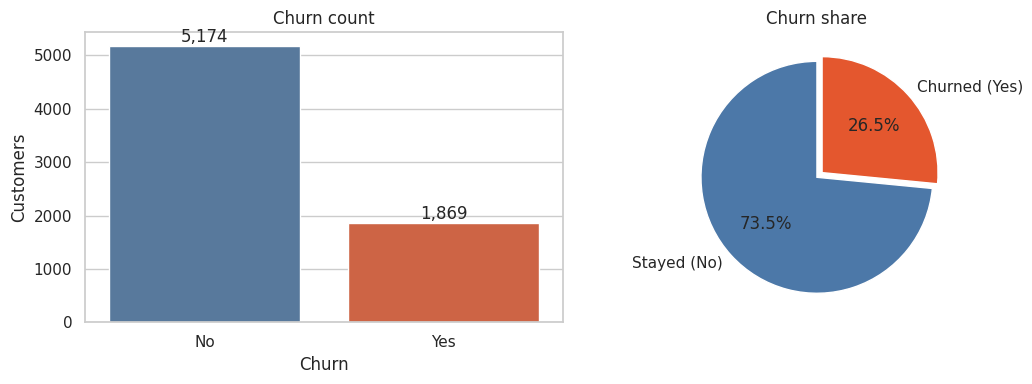

In [21]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
order = ['No', 'Yes']
sns.countplot(data=data, x='churn', order=order, palette=PALETTE, ax=ax[0])
for p in ax[0].patches:
    ax[0].annotate(f'{int(p.get_height()):,}', (p.get_x() + p.get_width() / 2, p.get_height()), ha='center', va='bottom')
ax[0].set_title('Churn count'); ax[0].set_xlabel('Churn'); ax[0].set_ylabel('Customers')
counts = data['churn'].value_counts().reindex(order)
ax[1].pie(counts, labels=['Stayed (No)', 'Churned (Yes)'], autopct='%1.1f%%', startangle=90,
          colors=[PALETTE['No'], PALETTE['Yes']], explode=(0, 0.06), wedgeprops={'edgecolor': 'white'})
ax[1].set_title('Churn share')
plt.tight_layout(); plt.show()

**What it shows:** the number and share of customers who stayed vs churned (count plot + pie chart).

**Key findings:** 5,174 customers (73.5%) stayed and 1,869 (26.5%) churned — roughly **2.8 stayers for every churner**. The target is **imbalanced**.

**Why it matters for prediction:** a model that always predicts "No" would already score ≈ 73.5% accuracy while catching zero churners, so accuracy alone is misleading. We will use stratified splitting, class weighting, and judge models mainly by **recall, F1 and ROC-AUC** of the churn class.

## 3.2 Numerical features — distributions (histograms)

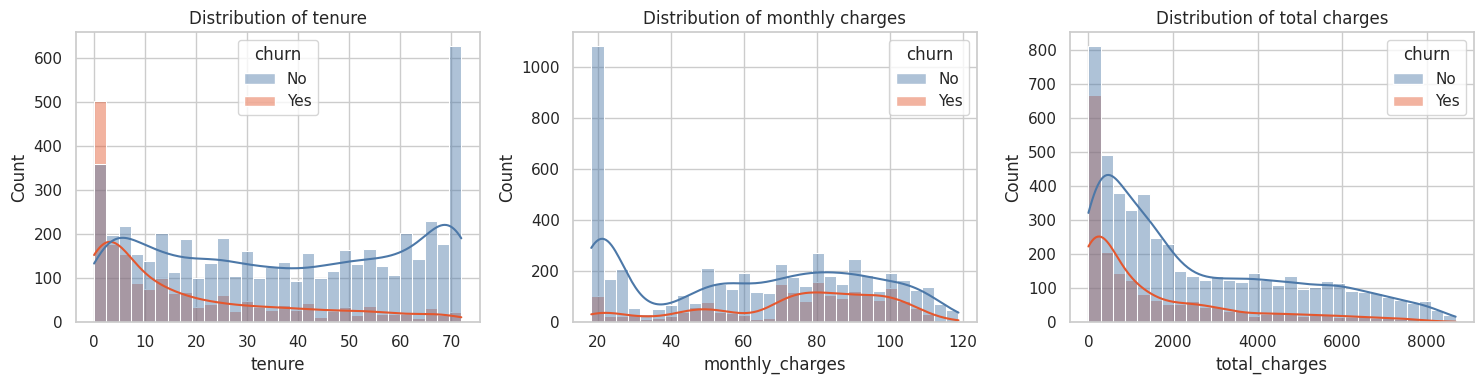

In [21]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, c in zip(axes, num_cols):
    sns.histplot(data=data, x=c, hue='churn', palette=PALETTE, bins=30, kde=True, alpha=0.45, ax=ax, hue_order=['No', 'Yes'])
    ax.set_title(f'Distribution of {c.replace("_", " ")}')
plt.tight_layout(); plt.show()

**What it shows:** the distribution of `tenure`, `monthly_charges` and `total_charges`, split by churn.

**Key findings:**
- `tenure` is U-shaped: many customers are very new (0–5 months) or very loyal (≈ 70 months). Churners are concentrated at the **low-tenure end**, loyal customers pile up at the high end.
- `monthly_charges` is bimodal: a large group pays ≈ $20 (phone-only customers), the rest spread between $50 and $110. Churners are shifted to the **higher-price** side.
- `total_charges` is strongly right-skewed, with churners concentrated at low totals (they leave before accumulating much).

**Why it matters:** short tenure and high monthly price both signal churn risk; the skew of `total_charges` is a reason to scale the features before training distance-based models.

## 3.3 Numerical features vs churn (box plots)

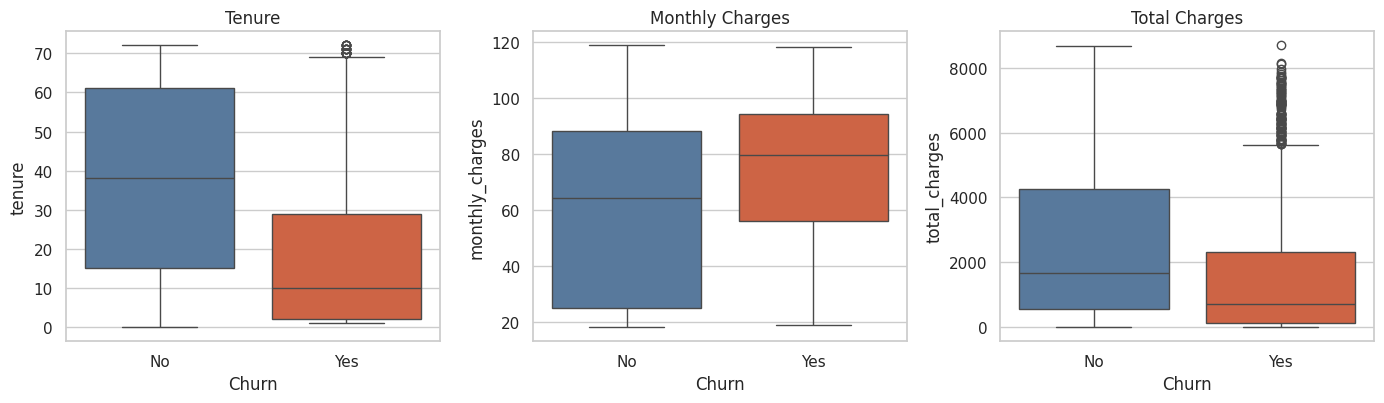

churn            median (stayed)  median (churned)
tenure                      38.0              10.0
monthly_charges             64.4              79.6
total_charges             1679.5             703.6


In [22]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4.2))
for ax, c in zip(axes, num_cols):
    sns.boxplot(data=data, x='churn', y=c, order=['No', 'Yes'], palette=PALETTE, ax=ax)
    ax.set_title(c.replace('_', ' ').title()); ax.set_xlabel('Churn')
plt.tight_layout(); plt.show()
print(data.groupby('churn')[num_cols].median().round(1).T.rename(columns={'No': 'median (stayed)', 'Yes': 'median (churned)'}))

**What it shows:** median, quartiles and spread of each numeric feature for stayers vs churners (no IQR outliers appear, confirming Part 2).

**Key findings:** the median tenure of churners is only **10 months vs 38 months** for stayers. Churners pay a higher median monthly charge (**$79.65 vs $64.43**) but have a lower median total charge (**$704 vs $1,680**) because they stay for a short time.

**Why it matters:** `tenure` separates the two groups most clearly, followed by `monthly_charges`; both are strong predictors. `total_charges` mostly reflects `tenure × monthly_charges`, so it is partly redundant.

## 3.4 Categorical features — customer demographics

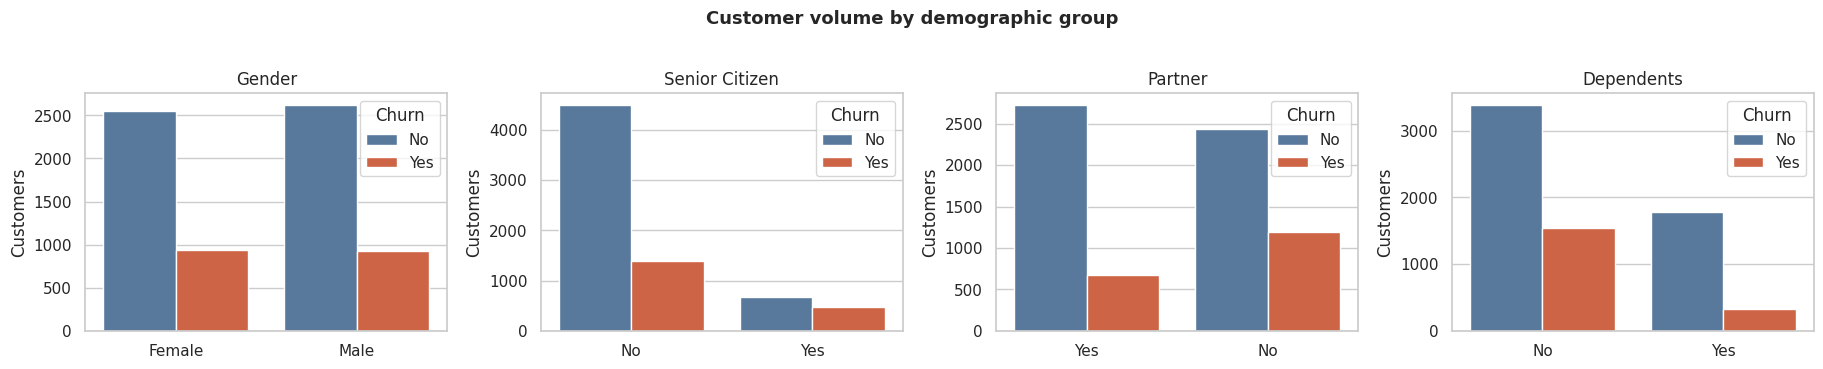

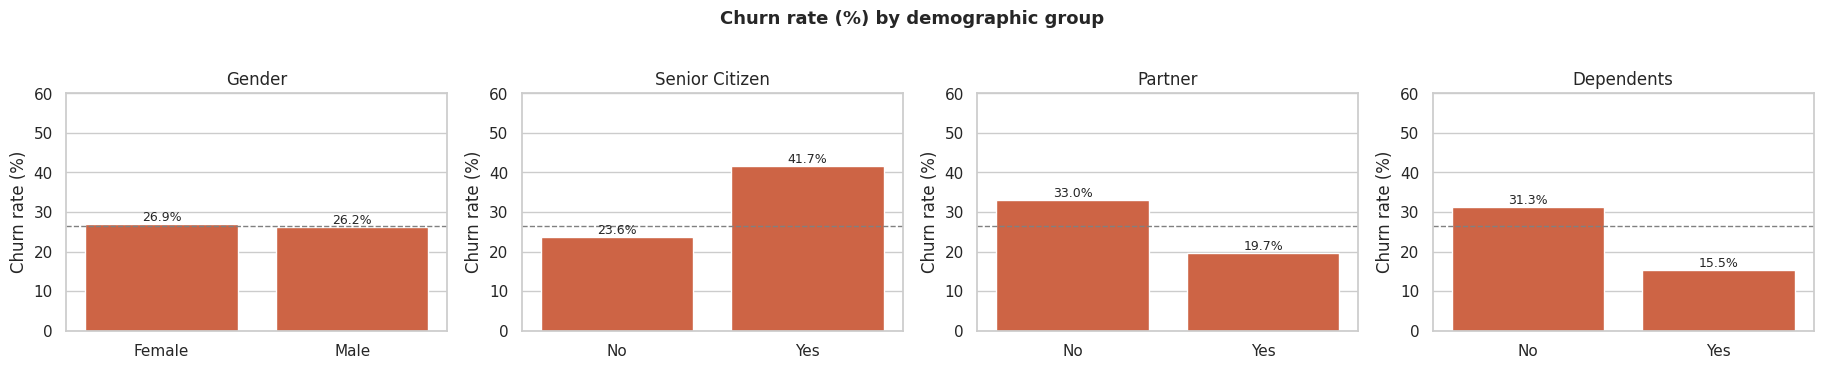

In [23]:
demo = ['gender', 'senior_citizen', 'partner', 'dependents']
count_grid(data, demo, ncols=4, title='Customer volume by demographic group')
rate_grid(data, demo, ncols=4, title='Churn rate (%) by demographic group')

**What it shows:** how many customers fall in each demographic group (top row) and the churn rate of each group (bottom row; dashed line = overall 26.5%).

**Key findings:**
- `gender` makes **no difference** (26.9% vs 26.2%).
- **Senior citizens churn far more**: 41.7% vs 23.6% (although they are only ≈ 16% of customers).
- Customers **without a partner** (33.0% vs 19.7%) and **without dependents** (31.3% vs 15.5%) churn more — people with family ties are more settled.

**Why it matters:** `senior_citizen`, `partner` and `dependents` carry real signal; `gender` can be dropped without loss.

## 3.5 Categorical features — services
Add-on columns only apply to customers who have internet, so those six charts use **internet customers only** (otherwise the 1,526 internet-less customers would blur the comparison).

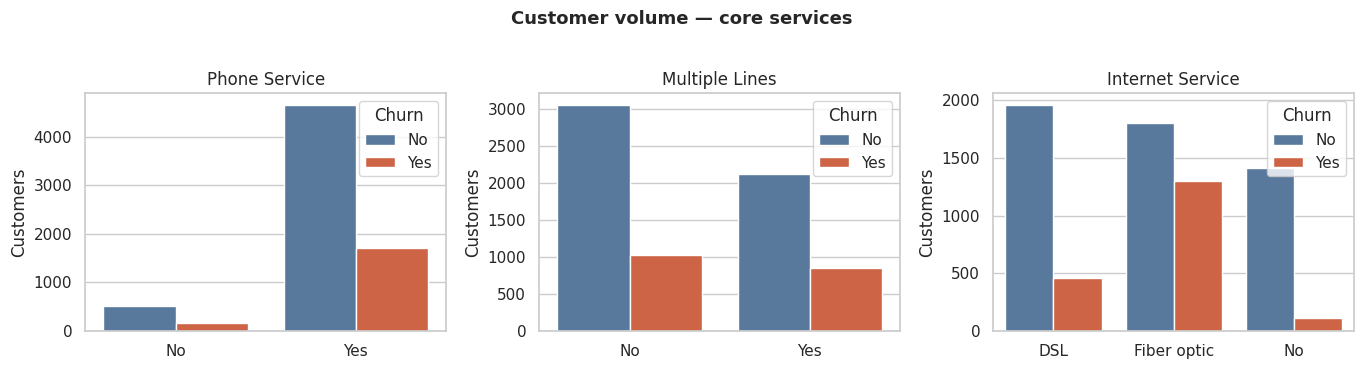

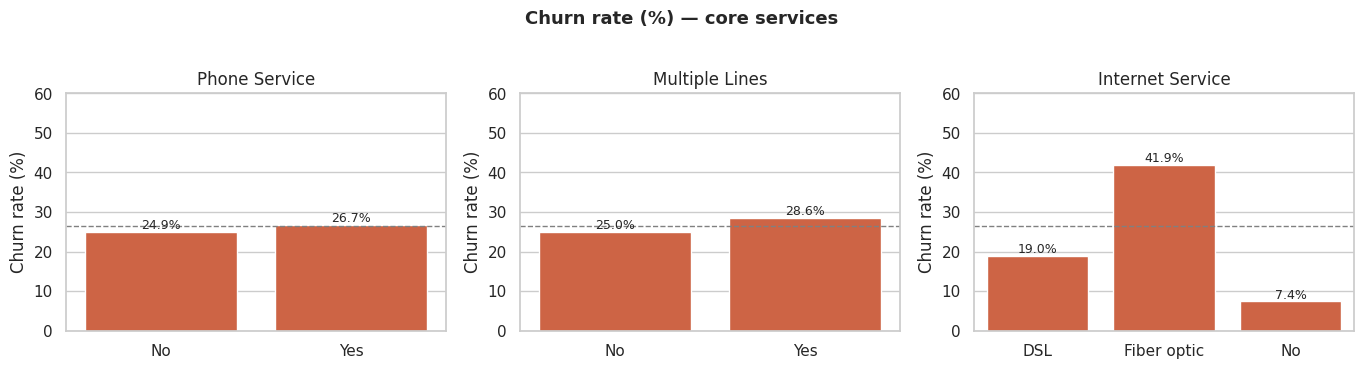

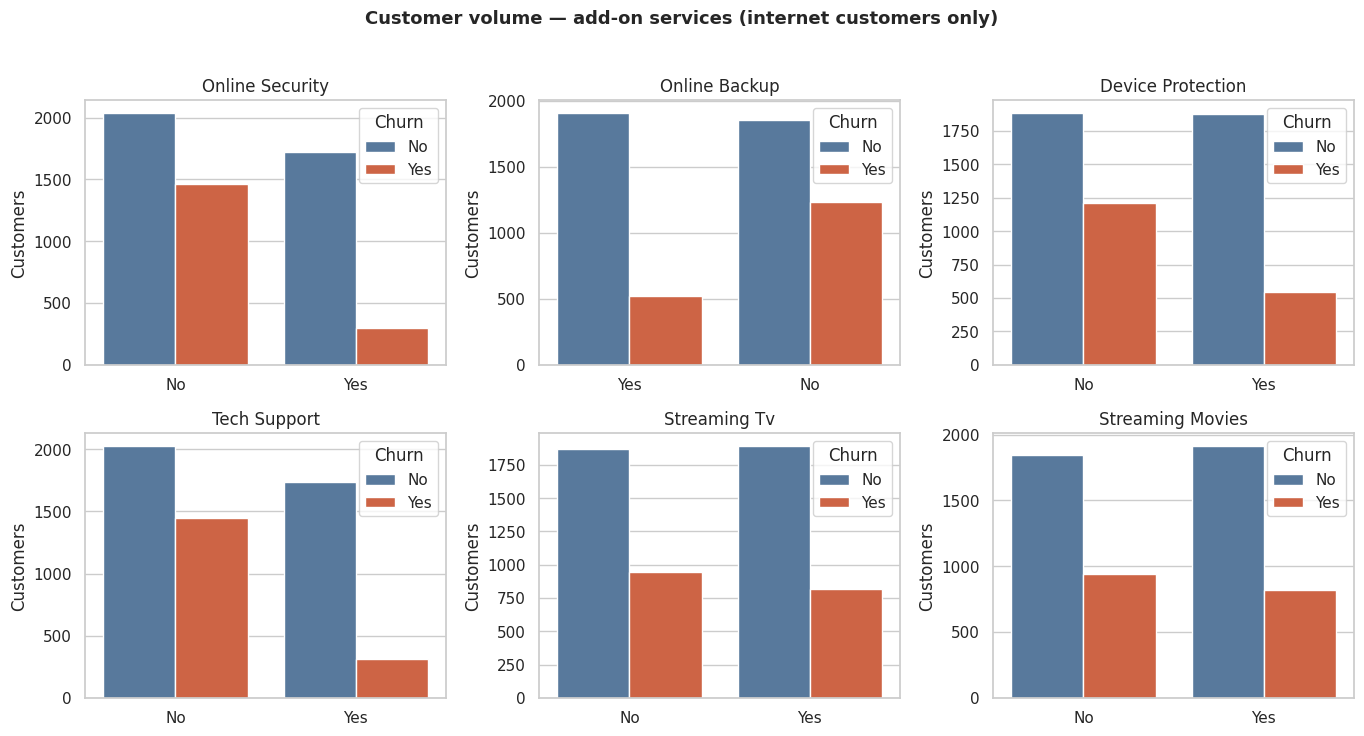

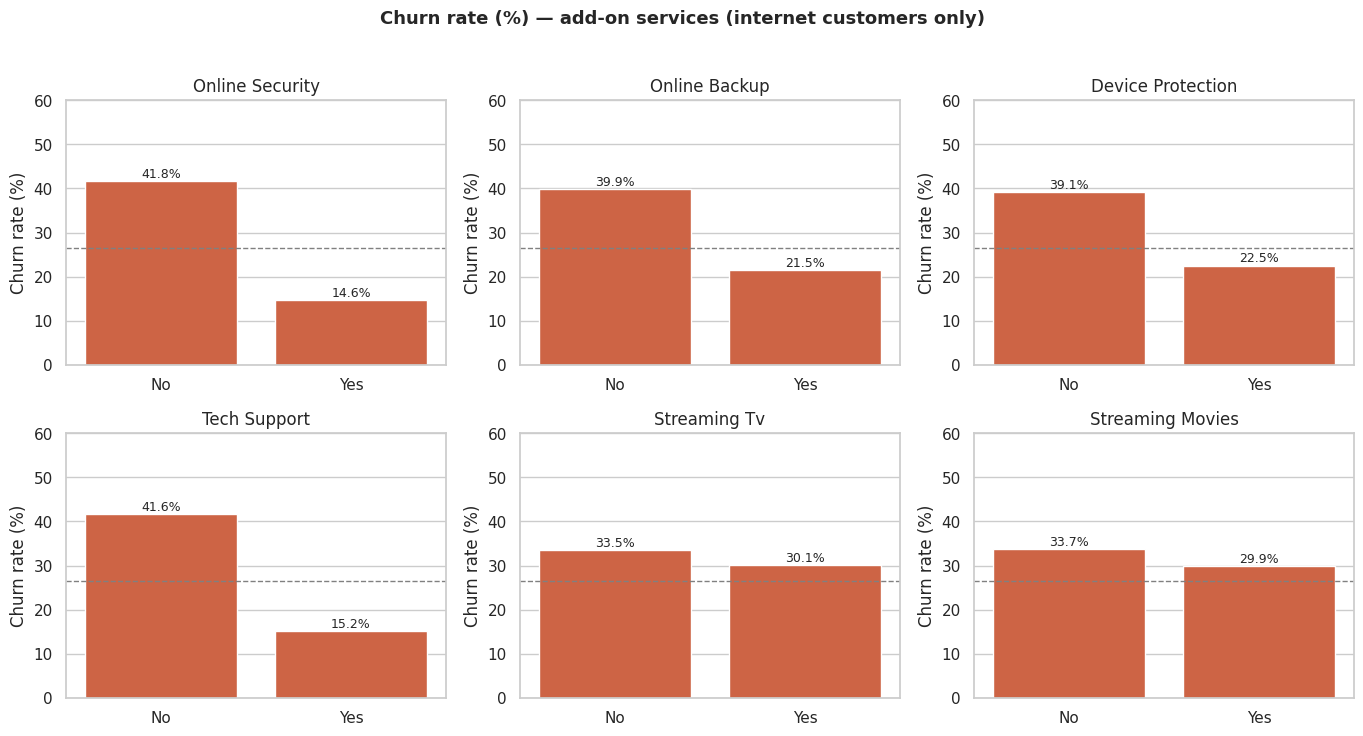

In [24]:
inet = data[data['internet_service'] != 'No']
core = ['phone_service', 'multiple_lines', 'internet_service']
count_grid(data, core, ncols=3, title='Customer volume — core services')
rate_grid(data, core, ncols=3, title='Churn rate (%) — core services')
count_grid(inet, addon_cols, ncols=3, title='Customer volume — add-on services (internet customers only)')
rate_grid(inet, addon_cols, ncols=3, title='Churn rate (%) — add-on services (internet customers only)')

**What it shows:** volume and churn rate for each service.

**Key findings:**
- **Internet type is a big factor:** fiber-optic customers churn at **41.9%**, DSL at 19.0%, and customers with no internet at only **7.4%**.
- `phone_service` (24.9% vs 26.7%) and `multiple_lines` (25.0% vs 28.6%) barely matter.
- Among internet customers, **protective add-ons cut churn sharply**: with `online_security` 14.6% vs 41.8% without; with `tech_support` 15.2% vs 41.6%; `online_backup` 21.5% vs 39.9%; `device_protection` 22.5% vs 39.1%.
- Streaming TV / movies make little difference (≈ 30% vs 34%).

**Which services reduce churn?** Online security, tech support, online backup and device protection. **Why it matters:** these four features and `internet_service` are valuable predictors; a customer on fiber with no security/support add-ons is a classic high-risk profile.

## 3.6 Categorical features — contract and billing

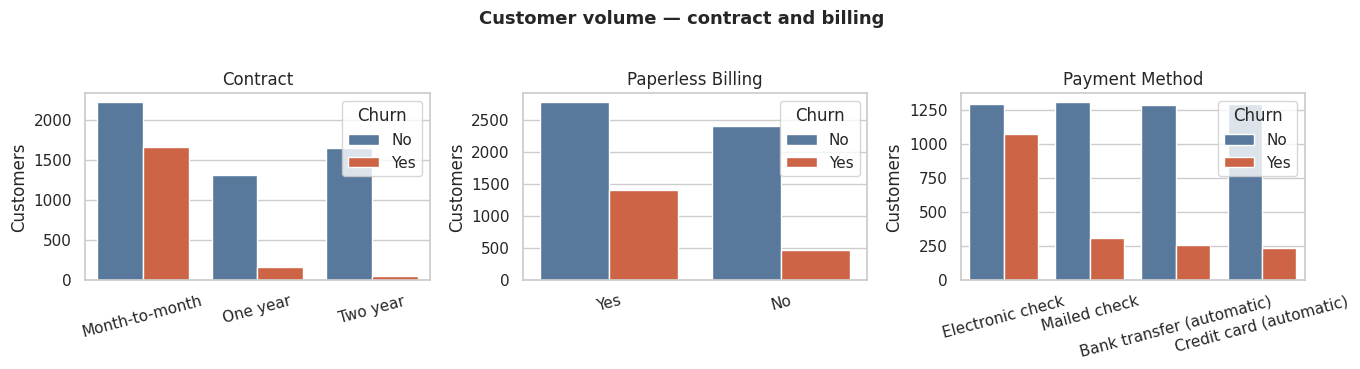

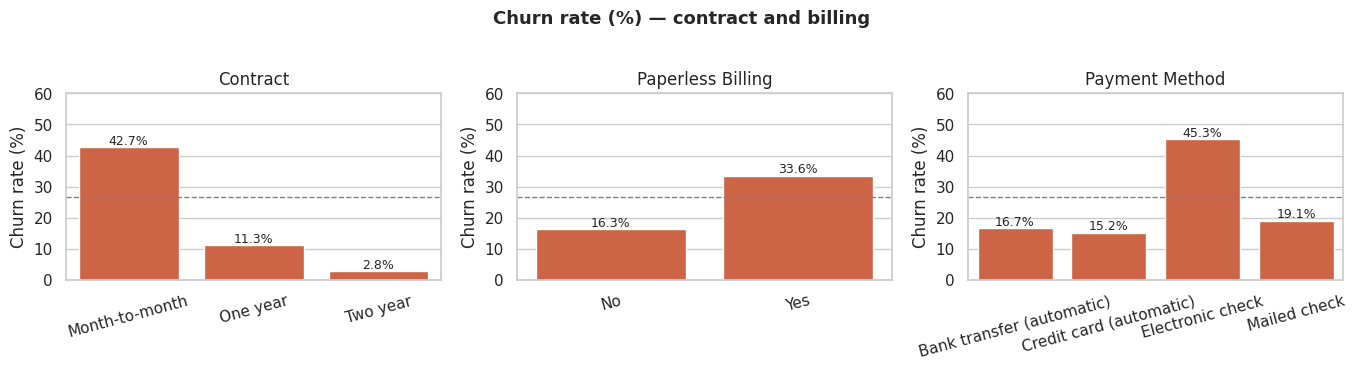

In [25]:
bill = ['contract', 'paperless_billing', 'payment_method']
count_grid(data, bill, ncols=3, rot=15, title='Customer volume — contract and billing')
rate_grid(data, bill, ncols=3, rot=15, title='Churn rate (%) — contract and billing')

**What it shows:** volume and churn rate by contract type, billing mode and payment method.

**Key findings:**
- **Contract is the strongest categorical driver:** month-to-month **42.7%**, one-year 11.3%, two-year **2.8%**. Month-to-month customers also make up **88.6% of all churners**.
- Paperless billing: 33.6% vs 16.3% for paper billing.
- **Electronic check users churn at 45.3%**, versus 15–19% for the other three payment methods (automatic bank transfer / credit card are the most loyal, ≈ 15–17%).

**Why it matters:** commitment (long contracts) and payment friction (manual electronic check) are excellent early-warning signals. Moving customers to longer contracts and automatic payment is an obvious retention lever.

## 3.7 Churn rate across tenure and price bands (bar charts)

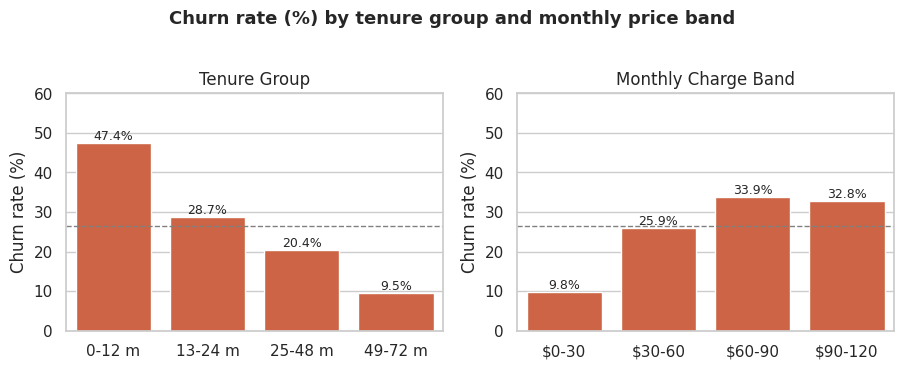

               mean  size
tenure_group             
0-12 m        0.474  2186
13-24 m       0.287  1024
25-48 m       0.204  1594
49-72 m       0.095  2239
                      mean  size
monthly_charge_band             
$0-30                0.098  1653
$30-60               0.259  1265
$60-90               0.339  2386
$90-120              0.328  1739


In [26]:
tmp = data.copy()
tmp['tenure_group'] = pd.cut(tmp['tenure'], [-1, 12, 24, 48, 72], labels=['0-12 m', '13-24 m', '25-48 m', '49-72 m'])
tmp['monthly_charge_band'] = pd.cut(tmp['monthly_charges'], [0, 30, 60, 90, 120], labels=['$0-30', '$30-60', '$60-90', '$90-120'])
rate_grid(tmp, ['tenure_group', 'monthly_charge_band'], ncols=2, title='Churn rate (%) by tenure group and monthly price band')
print(tmp.groupby('tenure_group', observed=True)['churn_num'].agg(['mean', 'size']).round(3))
print(tmp.groupby('monthly_charge_band', observed=True)['churn_num'].agg(['mean', 'size']).round(3))

**What it shows:** churn rate for binned `tenure` and `monthly_charges`.

**Key findings:** churn falls steadily with tenure — **47.4%** in the first year, 28.7% in year two, 20.4% in years 3–4 and only **9.5%** after four years. Price shows a rise-then-plateau pattern: **9.8%** for customers paying under $30, then 25.9%, 33.9% and 32.8% for the higher bands.

**Why it matters:** the first 12 months are the critical window for retention (55.5% of all churners leave within a year), and low-price phone-only customers are the safest.

## 3.8 Correlation heatmap

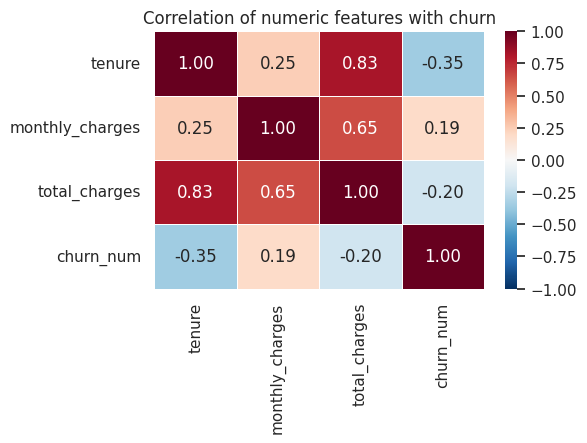

In [27]:
corr = data[num_cols + ['churn_num']].corr()
plt.figure(figsize=(6, 4.6))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='RdBu_r', center=0, vmin=-1, vmax=1, linewidths=0.5)
plt.title('Correlation of numeric features with churn'); plt.tight_layout(); plt.show()

**What it shows:** Pearson correlation between the numeric features and the (0/1) churn flag.

**Key findings:** `tenure` has the strongest relationship with churn (**r = −0.35**), then `total_charges` (−0.20) and `monthly_charges` (+0.19). `tenure` and `total_charges` are highly correlated (**0.83**), and `monthly_charges` and `total_charges` also correlate (0.65).

**Why it matters:** longer tenure → lower churn, higher price → higher churn. The strong tenure/total_charges correlation means those two features carry overlapping information (multicollinearity), which can hurt coefficient interpretation in Logistic Regression but is harmless for tree models. A full correlation analysis of all encoded features is done in Part 4.

## 3.9 Pairplot



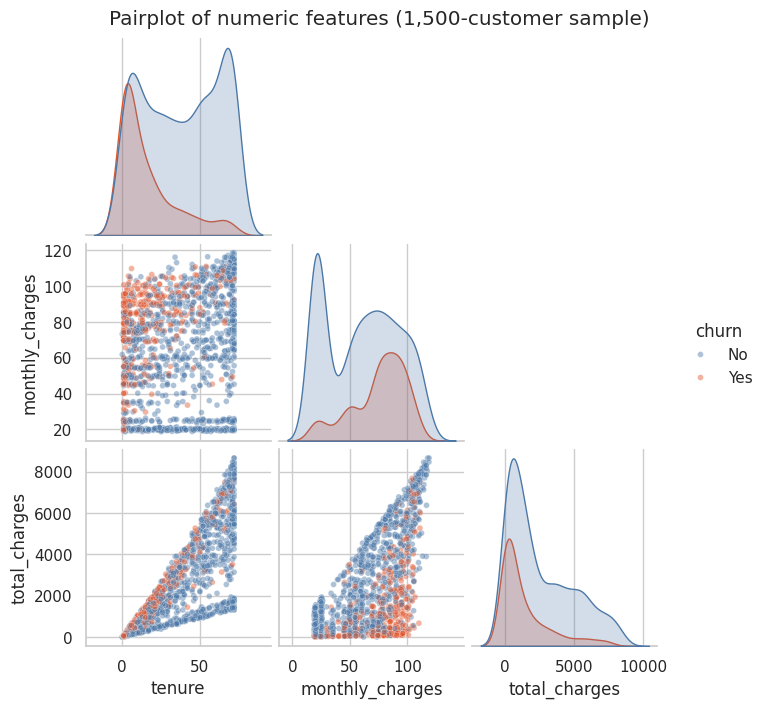

In [28]:
sample = data.sample(1500, random_state=SEED)
g = sns.pairplot(sample[num_cols + ['churn']], hue='churn', palette=PALETTE, hue_order=['No', 'Yes'],
                 plot_kws={'alpha': 0.45, 's': 18}, height=2.3, corner=True)
g.fig.suptitle('Pairplot of numeric features (1,500-customer sample)', y=1.02)
plt.show()

**What it shows:** pairwise scatter plots and distributions of the three numeric features, coloured by churn (random sample of 1,500 customers for readability).

**Key findings:** in the `tenure` × `monthly_charges` panel the orange (churned) points cluster in the **short-tenure / high-price** corner, while blue points dominate long tenures. `tenure` vs `total_charges` forms a clean fan shape (total ≈ tenure × monthly price).

**Why it matters:** the classes are only partly separable in these three features, which explains why we need the categorical features (contract, internet type…) and non-linear models to do well.

## 3.10 Which features have the strongest impact on churn?
For each categorical feature we measure the **spread** in churn rate between its best and worst category (add-ons measured on internet customers only), and compare with the numeric features' correlation.

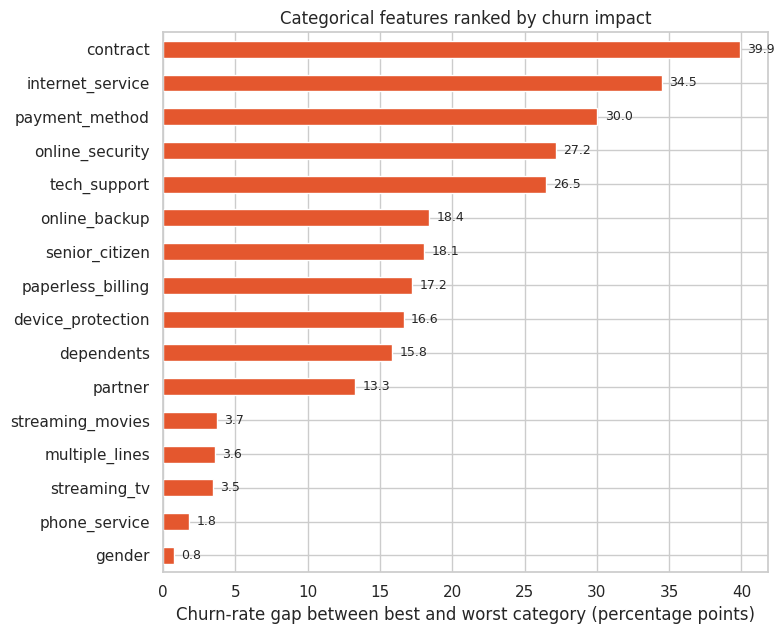

In [29]:
spread = {}
for c in cat_cols:
    frame = inet if c in addon_cols else data
    r = frame.groupby(c)['churn_num'].mean() * 100
    spread[c] = r.max() - r.min()
spread = pd.Series(spread).sort_values()

fig, ax = plt.subplots(figsize=(8, 6.5))
spread.plot.barh(color='#E4572E', ax=ax)
for i, v in enumerate(spread.values): ax.text(v + 0.5, i, f'{v:.1f}', va='center', fontsize=9)
ax.set_xlabel('Churn-rate gap between best and worst category (percentage points)')
ax.set_title('Categorical features ranked by churn impact')
plt.tight_layout(); plt.show()

**What it shows:** the percentage-point gap in churn rate between a feature's lowest-risk and highest-risk category.

**Key findings:** the top drivers are **`contract` (≈ 40 points), `internet_service` (≈ 35), `payment_method` (≈ 30), `online_security` and `tech_support` (≈ 27 and 26)**, followed by `online_backup`, `device_protection`, `senior_citizen` and `paperless_billing` (≈ 17–18 points). `gender`, `phone_service`, `multiple_lines` and the streaming columns are at the bottom (≈ 1–4 points). Together with `tenure` (r = −0.35) these are the strongest signals.

**Why it matters:** this ranking guides feature selection and tells the business where to act: contract length, security/support add-ons and payment method.

## 3.11 Final EDA summary — key insights

1. **Class imbalance:** only 26.5% of customers churn (1,869 of 7,043), so recall/F1/ROC-AUC matter more than accuracy.
2. **Contract type is the strongest driver:** month-to-month customers churn at 42.7% vs 2.8% for two-year contracts, and make up 88.6% of all churners.
3. **Tenure protects:** churn is 47.4% in the first year and 9.5% after four years; median tenure is 10 months for churners vs 38 for stayers (r = −0.35). 55.5% of churners leave within 12 months.
4. **Fiber-optic and electronic-check customers are high risk:** 41.9% (fiber) and 45.3% (electronic check) churn, vs ≈ 15–19% for DSL and the other payment methods; the combination with month-to-month contracts reaches 60.4%.
5. **Security and support services reduce churn:** among internet customers, online security (14.6% vs 41.8%), tech support (15.2% vs 41.6%), online backup and device protection cut churn roughly in half or more; streaming add-ons do not.
6. **Demographics:** senior citizens (41.7%), customers without partner (33.0%) or dependents (31.3%) churn more; **gender has no effect** (26.9% vs 26.2%).
7. **Price:** churners pay more per month (median $79.65 vs $64.43) but this is mostly a fiber effect; the cheapest, phone-only customers (< $30) churn at just 9.8%.
8. **Data quality:** no duplicates and no outliers; the only issue was 11 hidden blanks in `total_charges` (brand-new customers), fixed in Part 2.

---
# Part 4 — Feature Engineering

Order of work (chosen to **avoid data leakage**):
1. Feature creation, label encoding and one-hot encoding (deterministic, no statistics learned from the data, so safe to do before splitting).
2. **Part 5:** train/test split.
3. Feature scaling and feature selection — both *learn* something from the data (means, variances, mutual information), so they are fitted on the **training set only** and then applied to the test set.

### 4.1 Feature creation
New features that express business ideas the raw columns only hint at:

| New feature | Definition | Why |
|---|---|---|
| `num_addons` | number of the 6 add-on services the customer has | EDA showed protective add-ons cut churn; a count summarises engagement in one number |
| `avg_monthly_charge` | `total_charges / tenure` (monthly price if tenure = 0) | average price actually paid over the whole relationship |
| `charge_change` | `monthly_charges − avg_monthly_charge` | positive = current bill is higher than historic average (price rise / upgrade) |
| `has_family` | 1 if the customer has a partner **or** dependents | EDA showed both reduce churn |

### 4.2 Label encoding and 4.3 one-hot encoding
* **Label encoding** for the **binary** columns (Yes/No → 1/0, Female/Male → 1/0) and for the target (`LabelEncoder`: No → 0, Yes → 1). With only two categories there is no false ordering.
* **One-hot encoding** for the **nominal multi-category** columns `internet_service`, `contract`, `payment_method`. Label-encoding them would invent an order (e.g. DSL < Fiber) that distances/linear models would misread. We use fixed category lists so the encoding is identical at prediction time (needed for the Streamlit app).

In [30]:
df.columns


Index(['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents',
       'tenure', 'PhoneService', 'MultipleLines', 'InternetService',
       'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport',
       'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling',
       'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn'],
      dtype='object')

In [31]:
ADDONS = ['online_security', 'online_backup', 'device_protection', 'tech_support', 'streaming_tv', 'streaming_movies']
BINARY_COLS = ['gender', 'senior_citizen', 'partner', 'dependents', 'phone_service', 'multiple_lines',
               'online_security', 'online_backup', 'device_protection', 'tech_support',
               'streaming_tv', 'streaming_movies', 'paperless_billing']
BINARY_MAP = {'Yes': 1, 'No': 0, 'Female': 1, 'Male': 0}          # gender: Female = 1, Male = 0
NOMINAL = {
    'internet_service': ['DSL', 'Fiber optic', 'No'],
    'contract': ['Month-to-month', 'One year', 'Two year'],
    'payment_method': ['Bank transfer (automatic)', 'Credit card (automatic)', 'Electronic check', 'Mailed check'],
}

def engineer_features(d):
    # Turns a CLEANED dataframe (Part 2 format, without the target) into the numeric model matrix.
    d = d.copy()
    # --- feature creation
    d['num_addons'] = (d[ADDONS] == 'Yes').sum(axis=1)
    d['avg_monthly_charge'] = np.where(d['tenure'] > 0, d['total_charges'] / d['tenure'].replace(0, 1), d['monthly_charges'])
    d['charge_change'] = d['monthly_charges'] - d['avg_monthly_charge']
    d['has_family'] = ((d['partner'] == 'Yes') | (d['dependents'] == 'Yes')).astype(int)
    # --- label encoding of binary columns
    for c in BINARY_COLS:
        d[c] = d[c].map(BINARY_MAP).astype(int)
    # --- one-hot encoding of nominal columns (fixed categories)
    for c, cats in NOMINAL.items():
        dummies = pd.get_dummies(d[c].astype(pd.CategoricalDtype(cats)), prefix=c, dtype=int)
        d = pd.concat([d.drop(columns=c), dummies], axis=1)
    d.columns = [re.sub(r'[^0-9a-zA-Z_]+', '_', c).strip('_') for c in d.columns]
    return d

# Target: label encoding
le = LabelEncoder()
y = pd.Series(le.fit_transform(data['churn']), index=data.index, name='churn')
print('Target classes ->', dict(zip(le.classes_, le.transform(le.classes_))))

X = engineer_features(data.drop(columns=['churn', 'churn_num']))
print(f'\nFeature matrix: {X.shape[0]:,} rows x {X.shape[1]} columns')
print('Any missing values:', bool(X.isna().any().any()), '| all numeric:', all(np.issubdtype(t, np.number) for t in X.dtypes))
display(X.head())

Target classes -> {'No': np.int64(0), 'Yes': np.int64(1)}

Feature matrix: 7,043 rows x 30 columns
Any missing values: False | all numeric: True


,gender,senior_citizen,partner,dependents,tenure,phone_service,multiple_lines,online_security,online_backup,device_protection,tech_support,streaming_tv,streaming_movies,paperless_billing,monthly_charges,total_charges,num_addons,avg_monthly_charge,charge_change,has_family,internet_service_DSL,internet_service_Fiber_optic,internet_service_No,contract_Month_to_month,contract_One_year,contract_Two_year,payment_method_Bank_transfer_automatic,payment_method_Credit_card_automatic,payment_method_Electronic_check,payment_method_Mailed_check
0,1,0,1,0,1,0,0,0,1,0,0,0,0,1,29.85,29.85,1,29.850000,0.000000,1,1,0,0,1,0,0,0,0,1,0
1,0,0,0,0,34,1,0,1,0,1,0,0,0,0,56.95,1889.50,2,55.573529,1.376471,0,1,0,0,0,1,0,0,0,0,1
2,0,0,0,0,2,1,0,1,1,0,0,0,0,1,53.85,108.15,2,54.075000,-0.225000,0,1,0,0,1,0,0,0,0,0,1
3,0,0,0,0,45,0,0,1,0,1,1,0,0,0,42.30,1840.75,3,40.905556,1.394444,0,1,0,0,0,1,0,1,0,0,0
4,1,0,0,0,2,1,0,0,0,0,0,0,0,1,70.70,151.65,0,75.825000,-5.125000,0,0,1,0,1,0,0,0,0,1,0


### 4.4 Correlation of the engineered features with churn

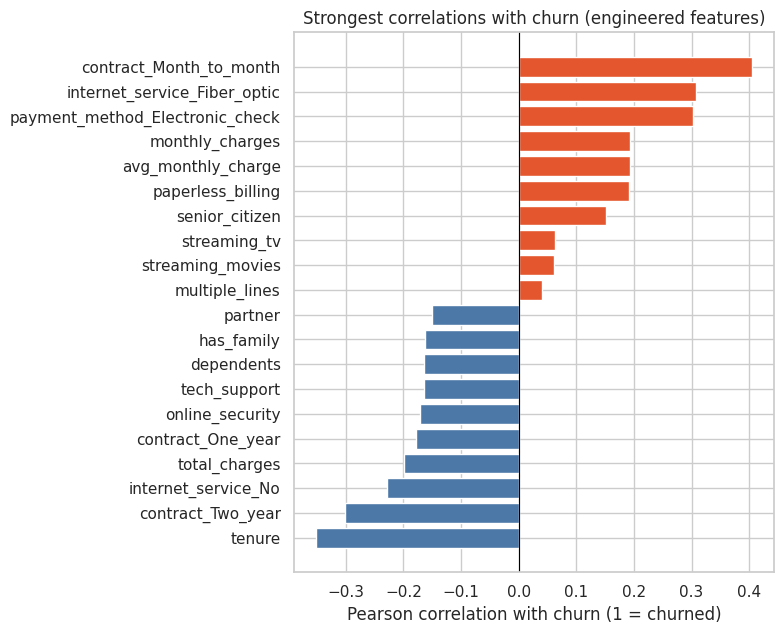

In [32]:
corr_y = X.corrwith(y).sort_values()
top = pd.concat([corr_y.head(10), corr_y.tail(10)])
fig, ax = plt.subplots(figsize=(8, 6.5))
colors = ['#4C78A8' if v < 0 else '#E4572E' for v in top.values]
ax.barh(top.index, top.values, color=colors)
ax.axvline(0, color='black', lw=0.8)
ax.set_title('Strongest correlations with churn (engineered features)')
ax.set_xlabel('Pearson correlation with churn (1 = churned)')
plt.tight_layout(); plt.show()

**What it shows:** the 10 most negative (blue, protective) and 10 most positive (orange, risk) correlations between encoded features and churn.

**Key findings:** the strongest *risk* factors are `contract_Month_to_month` (r ≈ +0.40), `internet_service_Fiber_optic` (+0.31) and `payment_method_Electronic_check` (+0.30), followed by `monthly_charges`, `avg_monthly_charge`, `paperless_billing` and `senior_citizen`. The strongest *protective* factors are `tenure` (−0.35), `contract_Two_year` (−0.30) and `internet_service_No` (−0.23), then `total_charges`, one-year contracts, `online_security`, `tech_support` and the family flags (`dependents`, `has_family`, `partner`). This agrees with the EDA. Of the new features, `has_family` (−0.16) and `avg_monthly_charge` (+0.19) have clear linear signal; `num_addons` is weaker (−0.09) and `charge_change` has almost no *linear* correlation (≈ 0.00) — but the next section shows `charge_change` is very informative in a non-linear way.

**Why it matters:** the encoded dataset preserves the patterns found in EDA, so models should be able to learn them. Pearson correlation only sees linear relationships, which is one reason to also use mutual information and tree-based importance for feature selection.

---
# Part 5 — Train-Test Split

* **80% train / 20% test.**
* `random_state=42` → identical split on every run (reproducibility).
* `stratify=y` → both sets keep the same 26.5% churn rate, which is essential with an imbalanced target.

In [50]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=SEED, stratify=y)

print(f'Train: {X_train.shape[0]:,} rows | churn rate {y_train.mean():.3%}')
print(f'Test : {X_test.shape[0]:,} rows | churn rate {y_test.mean():.3%}')

Train: 5,634 rows | churn rate 26.535%
Test : 1,409 rows | churn rate 26.544%


### 44.5 Feature Scaling
- Used StandardScaler to bring numerical features to a similar scale (mean = 0, std = 1).
- Scaling helps KNN, SVM, and Logistic Regression perform better.
- Binary 0/1 features were left unchanged.
- Tree-based models generally don't require scaling.
- To avoid data leakage: used fit_transform() on training data and transform() on test data only.

In [49]:
scale_cols = ['tenure', 'monthly_charges', 'total_charges', 'avg_monthly_charge', 'charge_change', 'num_addons']
scaler = StandardScaler()

X_train_s, X_test_s = X_train.copy(), X_test.copy()
X_train_s[scale_cols] = scaler.fit_transform(X_train[scale_cols])
X_test_s[scale_cols] = scaler.transform(X_test[scale_cols])

print("Train Means:")
print(X_train_s[scale_cols].mean().round(3))

print("\nTrain Standard Deviations:")
print(X_train_s[scale_cols].std().round(3))


Train Means:
tenure               -0.0
monthly_charges      -0.0
total_charges         0.0
avg_monthly_charge   -0.0
charge_change        -0.0
num_addons            0.0
dtype: float64

Train Standard Deviations:
tenure                1.0
monthly_charges       1.0
total_charges         1.0
avg_monthly_charge    1.0
charge_change         1.0
num_addons            1.0
dtype: float64


### 4.6 Feature selection (training set only)
We rank features with **mutual information** (captures non-linear dependence on churn) and with **Random Forest importance**, then drop features that carry essentially **no information** about churn (mutual information < 0.001). Removing noise features reduces overfitting and training time.

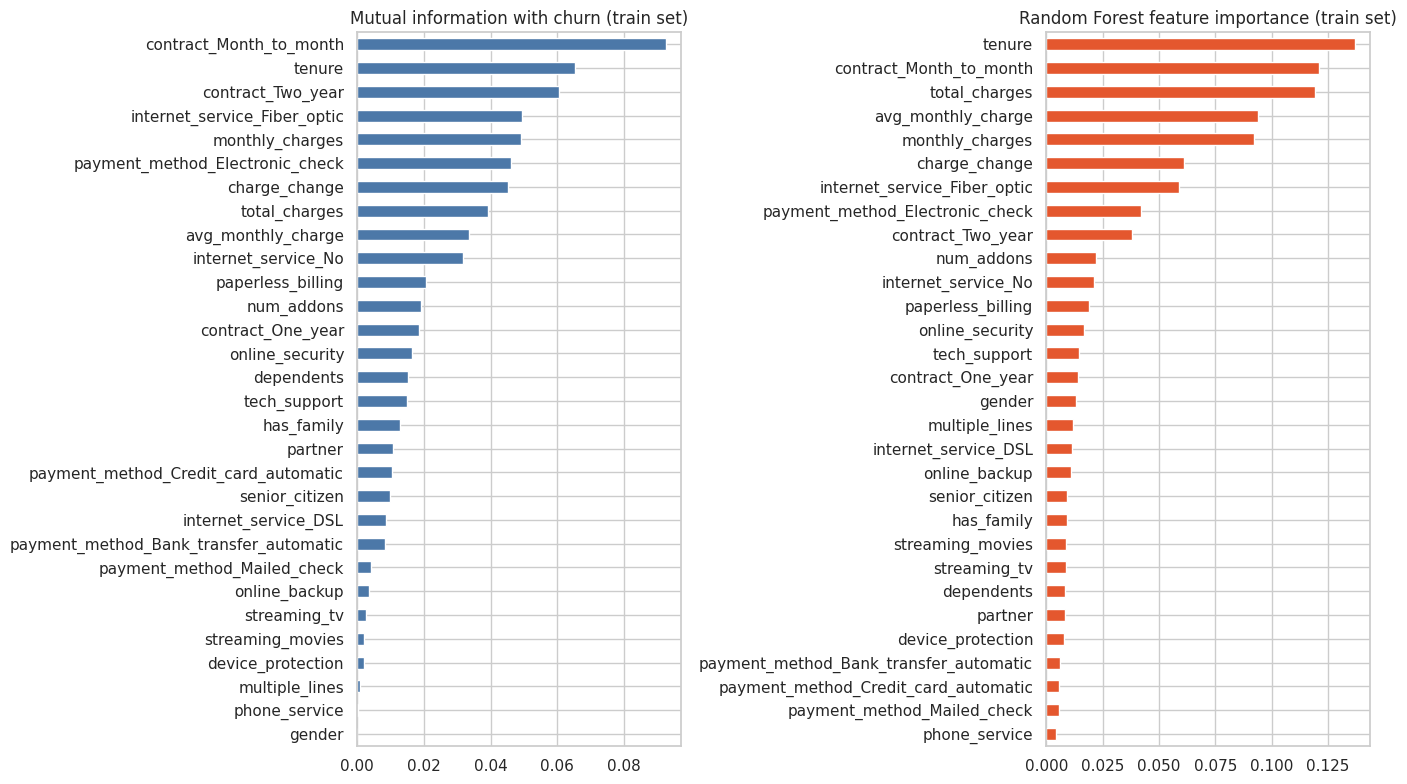

Dropped (MI < 0.001): ['gender', 'phone_service', 'multiple_lines']
Kept 27 of 30 features.


In [35]:
mi = pd.Series(mutual_info_classif(X_train_s, y_train, random_state=SEED, discrete_features=[c not in scale_cols for c in X_train_s.columns]),
               index=X_train_s.columns).sort_values()
rf_imp = pd.Series(RandomForestClassifier(n_estimators=300, min_samples_leaf=5, random_state=SEED, n_jobs=-1).fit(X_train_s, y_train).feature_importances_,
                   index=X_train_s.columns).sort_values()

fig, ax = plt.subplots(1, 2, figsize=(14, 8))
mi.plot.barh(ax=ax[0], color='#4C78A8'); ax[0].set_title('Mutual information with churn (train set)')
rf_imp.plot.barh(ax=ax[1], color='#E4572E'); ax[1].set_title('Random Forest feature importance (train set)')
plt.tight_layout(); plt.show()

MI_THRESHOLD = 0.001
dropped = list(mi[mi < MI_THRESHOLD].index)
selected = [c for c in X_train_s.columns if c not in dropped]
print(f'Dropped (MI < {MI_THRESHOLD}):', dropped)
print(f'Kept {len(selected)} of {X_train_s.shape[1]} features.')

**What it shows:** two independent rankings of feature usefulness, both computed on the training data.

**Key findings:** both rankings agree that `contract_Month_to_month`, `tenure`, the three charge features (`total_charges`, `avg_monthly_charge`, `monthly_charges`), our engineered **`charge_change`**, `internet_service_Fiber_optic`, `payment_method_Electronic_check` and `contract_Two_year` are the most informative features. The engineered `charge_change` ranks 7th by mutual information and 6th by Random Forest importance even though its linear correlation with churn is ≈ 0, so feature creation paid off. At the bottom, **`gender`, `phone_service` and `multiple_lines` have mutual information below 0.001** and are dropped, matching the EDA result that gender, phone service and multiple lines are irrelevant.

**Why it matters:** 27 of the 30 features are kept — every feature that carries signal — and only the three useless ones are removed. The selected feature list is saved with the model for the Streamlit app.

In [36]:
Xtr, Xte = X_train_s[selected], X_test_s[selected]
ytr, yte = y_train, y_test
sw = compute_sample_weight('balanced', ytr)      # per-row weights that balance the 2 classes (for models without class_weight)
print('Final model inputs:', Xtr.shape, Xte.shape)

Final model inputs: (5634, 27) (1409, 27)


---
# Part 6 — Model Building

Six different classifiers are trained and compared. To deal with the class imbalance, every model that supports it uses **balanced class weights** (the minority class counts more during training), so recall on churners is not sacrificed.
All models are evaluated at the default 0.5 decision threshold on the same untouched test set.

A shared helper trains a model, predicts, and stores accuracy, precision, recall, F1, ROC-AUC (all for the churn class = 1) plus train accuracy (to spot overfitting).

In [37]:
results, fitted = [], {}

def run_model(name, model, group, use_sw=False):
    t0 = time.time()
    model.fit(Xtr, ytr, sample_weight=sw) if use_sw else model.fit(Xtr, ytr)
    train_time = time.time() - t0
    pred = model.predict(Xte)
    proba = model.predict_proba(Xte)[:, 1]
    results.append({
        'Model': name, 'Type': group,
        'Accuracy': accuracy_score(yte, pred), 'Precision': precision_score(yte, pred),
        'Recall': recall_score(yte, pred), 'F1': f1_score(yte, pred), 'ROC_AUC': roc_auc_score(yte, proba),
        'Train_Acc': accuracy_score(ytr, model.predict(Xtr)), 'Fit_s': train_time})
    fitted[name] = {'model': model, 'pred': pred, 'proba': proba}
    r = results[-1]
    print(f"{name:22s} acc={r['Accuracy']:.3f}  prec={r['Precision']:.3f}  rec={r['Recall']:.3f}  f1={r['F1']:.3f}  auc={r['ROC_AUC']:.3f}  ({train_time:.1f}s)")

In [38]:
base_models = {
    'Logistic Regression': LogisticRegression(max_iter=2000, class_weight='balanced', random_state=SEED),
    'Decision Tree':       DecisionTreeClassifier(max_depth=5, min_samples_leaf=20, class_weight='balanced', random_state=SEED),
    'Random Forest':       RandomForestClassifier(n_estimators=300, max_depth=8, min_samples_leaf=5, class_weight='balanced', random_state=SEED, n_jobs=-1),
    'KNN':                 KNeighborsClassifier(n_neighbors=25),
    'SVM (RBF)':           SVC(kernel='rbf', C=1.0, class_weight='balanced', probability=True, random_state=SEED),
    'Naive Bayes':         GaussianNB(),
}
for name, model in base_models.items():
    run_model(name, model, 'Individual')

Logistic Regression    acc=0.740  prec=0.506  rec=0.797  f1=0.619  auc=0.841  (0.0s)
Decision Tree          acc=0.749  prec=0.519  rec=0.786  f1=0.625  auc=0.832  (0.0s)
Random Forest          acc=0.767  prec=0.543  rec=0.778  f1=0.640  auc=0.844  (1.9s)
KNN                    acc=0.788  prec=0.606  rec=0.575  f1=0.590  auc=0.830  (0.0s)
SVM (RBF)              acc=0.748  prec=0.517  rec=0.770  f1=0.619  auc=0.823  (9.4s)
Naive Bayes            acc=0.737  prec=0.504  rec=0.757  f1=0.605  auc=0.821  (0.0s)


**Model notes:**
* **Logistic Regression** – linear baseline, interpretable coefficients.
* **Decision Tree** – depth limited to 5 and ≥ 20 samples per leaf to prevent memorising the training set.
* **Random Forest** – many de-correlated trees averaged; handles non-linearity and interactions.
* **KNN** (k = 25) – a large *k* smooths noise; it has no class-weight option, so it tends to favour the majority class.
* **SVM (RBF)** – non-linear margin classifier, benefits strongly from the scaling done above.
* **Gaussian Naive Bayes** – fast probabilistic baseline that assumes feature independence (violated here, e.g. tenure vs total_charges).

---
# Part 7 — Ensemble Learning

Ensembles combine several models to get a more accurate and stable one.

| Technique | Idea | Models used |
|---|---|---|
| **Bagging** | train many models on bootstrap samples in parallel and average them → lowers variance | 100 decision trees |
| **Boosting** | train models sequentially, each fixing the errors of the previous → lowers bias | AdaBoost, Gradient Boosting, Hist Gradient Boosting |
| **Voting** | average the predicted probabilities of different model families (soft voting) | Logistic Regression + Random Forest + Gradient Boosting |
| **Stacking** (bonus) | a meta-model (Logistic Regression) learns how to best combine the predictions of base models, using cross-validated predictions | Logistic Regression, Random Forest, Gradient Boosting, Naive Bayes, SVM |

In [39]:
# ---- Bagging
bagging = BaggingClassifier(
    estimator=DecisionTreeClassifier(max_depth=6, min_samples_leaf=10, class_weight='balanced', random_state=SEED),
    n_estimators=100, max_samples=0.8, random_state=SEED, n_jobs=-1)
run_model('Bagging (Trees)', bagging, 'Ensemble')

# ---- Boosting
ada = AdaBoostClassifier(estimator=DecisionTreeClassifier(max_depth=2, random_state=SEED), n_estimators=200, learning_rate=0.5, random_state=SEED)
run_model('AdaBoost', ada, 'Ensemble', use_sw=True)

gb = GradientBoostingClassifier(n_estimators=200, learning_rate=0.05, max_depth=3, subsample=0.8, random_state=SEED)
run_model('Gradient Boosting', gb, 'Ensemble', use_sw=True)

hgb = HistGradientBoostingClassifier(max_iter=200, learning_rate=0.05, max_depth=4, class_weight='balanced', random_state=SEED)
run_model('Hist Gradient Boosting', hgb, 'Ensemble')

Bagging (Trees)        acc=0.768  prec=0.544  rec=0.770  f1=0.638  auc=0.845  (5.8s)
AdaBoost               acc=0.751  prec=0.520  rec=0.805  f1=0.632  auc=0.841  (3.0s)
Gradient Boosting      acc=0.748  prec=0.516  rec=0.799  f1=0.627  auc=0.841  (4.0s)
Hist Gradient Boosting acc=0.751  prec=0.520  rec=0.789  f1=0.627  auc=0.841  (0.5s)


In [40]:
# ---- Voting (soft): average probabilities of 3 different model families
voting = VotingClassifier(
    estimators=[('lr', LogisticRegression(max_iter=2000, class_weight='balanced', random_state=SEED)),
                ('rf', RandomForestClassifier(n_estimators=300, max_depth=8, min_samples_leaf=5, class_weight='balanced', random_state=SEED, n_jobs=-1)),
                ('gb', GradientBoostingClassifier(n_estimators=200, learning_rate=0.05, max_depth=3, subsample=0.8, random_state=SEED))],
    voting='soft')
run_model('Voting (soft)', voting, 'Ensemble', use_sw=True)

# ---- Stacking (bonus): meta Logistic Regression on 5-fold out-of-fold predictions of the base models
stacking = StackingClassifier(
    estimators=[('lr', LogisticRegression(max_iter=2000, class_weight='balanced', random_state=SEED)),
                ('rf', RandomForestClassifier(n_estimators=200, max_depth=8, min_samples_leaf=5, class_weight='balanced', random_state=SEED, n_jobs=-1)),
                ('gb', GradientBoostingClassifier(n_estimators=150, learning_rate=0.05, max_depth=3, subsample=0.8, random_state=SEED)),
                ('nb', GaussianNB()),
                ('svm', SVC(kernel='rbf', class_weight='balanced', random_state=SEED))],
    final_estimator=LogisticRegression(max_iter=2000, class_weight='balanced', random_state=SEED),
    cv=5, n_jobs=1)
run_model('Stacking', stacking, 'Ensemble', use_sw=True)

Voting (soft)          acc=0.691  prec=0.457  rec=0.877  f1=0.601  auc=0.846  (5.2s)
Stacking               acc=0.647  prec=0.424  rec=0.930  f1=0.583  auc=0.847  (33.6s)


### Ensemble vs individual models

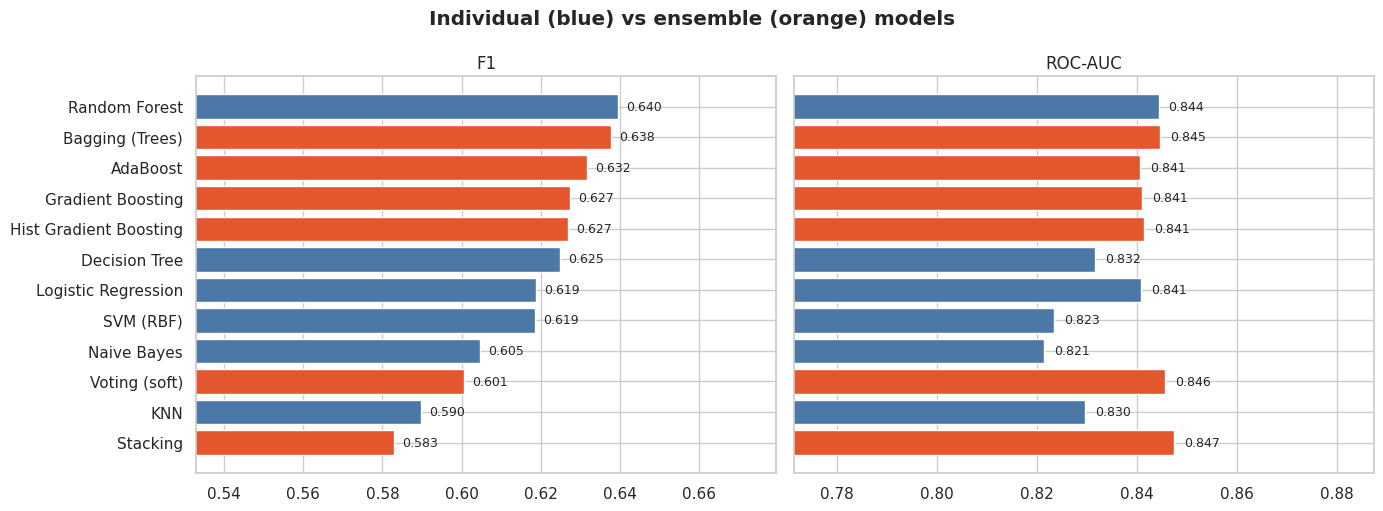

Mean F1      individual: 0.616 | ensemble: 0.618
Mean ROC-AUC individual: 0.832 | ensemble: 0.843


In [41]:
res = pd.DataFrame(results)
cols = ['Model', 'Type', 'Accuracy', 'Precision', 'Recall', 'F1', 'ROC_AUC']
fig, ax = plt.subplots(1, 2, figsize=(14, 5.2), sharey=True)
order = res.sort_values('F1')['Model']
for a, metric in zip(ax, ['F1', 'ROC_AUC']):
    d = res.set_index('Model').loc[order]
    a.barh(d.index, d[metric], color=['#E4572E' if t == 'Ensemble' else '#4C78A8' for t in d['Type']])
    for i, v in enumerate(d[metric]): a.text(v + 0.002, i, f'{v:.3f}', va='center', fontsize=9)
    a.set_xlim(d[metric].min() - 0.05, d[metric].max() + 0.04); a.set_title(metric.replace('_', '-'))
fig.suptitle('Individual (blue) vs ensemble (orange) models', fontweight='bold')
plt.tight_layout(); plt.show()
print('Mean F1      individual: %.3f | ensemble: %.3f' % (res[res.Type == 'Individual'].F1.mean(), res[res.Type == 'Ensemble'].F1.mean()))
print('Mean ROC-AUC individual: %.3f | ensemble: %.3f' % (res[res.Type == 'Individual'].ROC_AUC.mean(), res[res.Type == 'Ensemble'].ROC_AUC.mean()))

**What it shows:** F1 and ROC-AUC of the 6 individual models (blue) and the 6 ensembles (orange) on the same test set.

**Key findings:**
- **Ensembles are consistently strong but not dramatically better.** Mean F1 is slightly higher for ensembles, and their ROC-AUC is 0.841–0.847 versus 0.821–0.844 for the individual models. The best individual model (Random Forest, which is itself a bagging ensemble) has the best F1 overall (0.640), with Bagging of trees essentially tied (0.638).
- **Boosting** (AdaBoost, Gradient Boosting, Hist Gradient Boosting) reaches F1 0.627–0.632 and AUC ≈ 0.841, with higher recall (0.79–0.81) but lower precision than Random Forest.
- **Voting** has the highest recall of all (0.834) at the price of the lowest precision among ensembles (0.493). **Stacking** has the best ROC-AUC (0.847) and the second-highest recall (0.824) but takes about 16 s to fit versus about 1 s for Random Forest and does not improve F1 (0.628).
- With only 374 churners in the test set, differences of about 0.01 in F1 or AUC are within random variation, so the honest reading is that Random Forest, Bagging, Boosting, Voting and Stacking are all close; the ensembles mainly buy a bit more AUC/recall and stability, not a large jump.

**Why it matters:** because no model clearly dominates, the choice should consider simplicity, speed and the business trade-off between recall and precision (Part 8–9).

---
# Part 8 — Model Evaluation

Metrics (churn = positive class):
* **Accuracy** – share of all predictions that are right (misleading with 26.5% churners).
* **Precision** – of the customers predicted to churn, how many really churn (cost of wasted retention offers).
* **Recall** – of the customers who really churn, how many we catch (cost of lost customers).
* **F1** – harmonic mean of precision and recall; our main selection metric.
* **ROC-AUC** – ranking quality independent of the threshold.

In [42]:
res = pd.DataFrame(results)
table = res[['Model', 'Type', 'Accuracy', 'Precision', 'Recall', 'F1', 'ROC_AUC', 'Train_Acc']].sort_values(['F1', 'ROC_AUC'], ascending=False).reset_index(drop=True)
table.index = table.index + 1
display(table.round(4))
best_name = table.loc[1, 'Model']
print('Best model by F1 (ties broken by ROC-AUC):', best_name)

,Model,Type,Accuracy,Precision,Recall,F1,ROC_AUC,Train_Acc
1,Random Forest,Individual,0.7672,0.5429,0.7781,0.6396,0.8443,0.7968
2,Bagging (Trees),Ensemble,0.7679,0.5444,0.7701,0.6379,0.8445,0.7843
3,AdaBoost,Ensemble,0.7509,0.5199,0.8048,0.6317,0.8406,0.7618
4,Gradient Boosting,Ensemble,0.7480,0.5164,0.7995,0.6275,0.8409,0.7803
5,Hist Gradient Boosting,Ensemble,0.7509,0.5203,0.7888,0.6270,0.8413,0.7969
6,Decision Tree,Individual,0.7495,0.5185,0.7861,0.6249,0.8316,0.7577
7,Logistic Regression,Individual,0.7395,0.5059,0.7968,0.6189,0.8408,0.7506
8,SVM (RBF),Individual,0.7480,0.5171,0.7701,0.6187,0.8234,0.7670
9,Naive Bayes,Individual,0.7374,0.5036,0.7567,0.6047,0.8214,0.7464
10,Voting (soft),Ensemble,0.6906,0.4568,0.8770,0.6007,0.8456,0.7169


Best model by F1 (ties broken by ROC-AUC): Random Forest


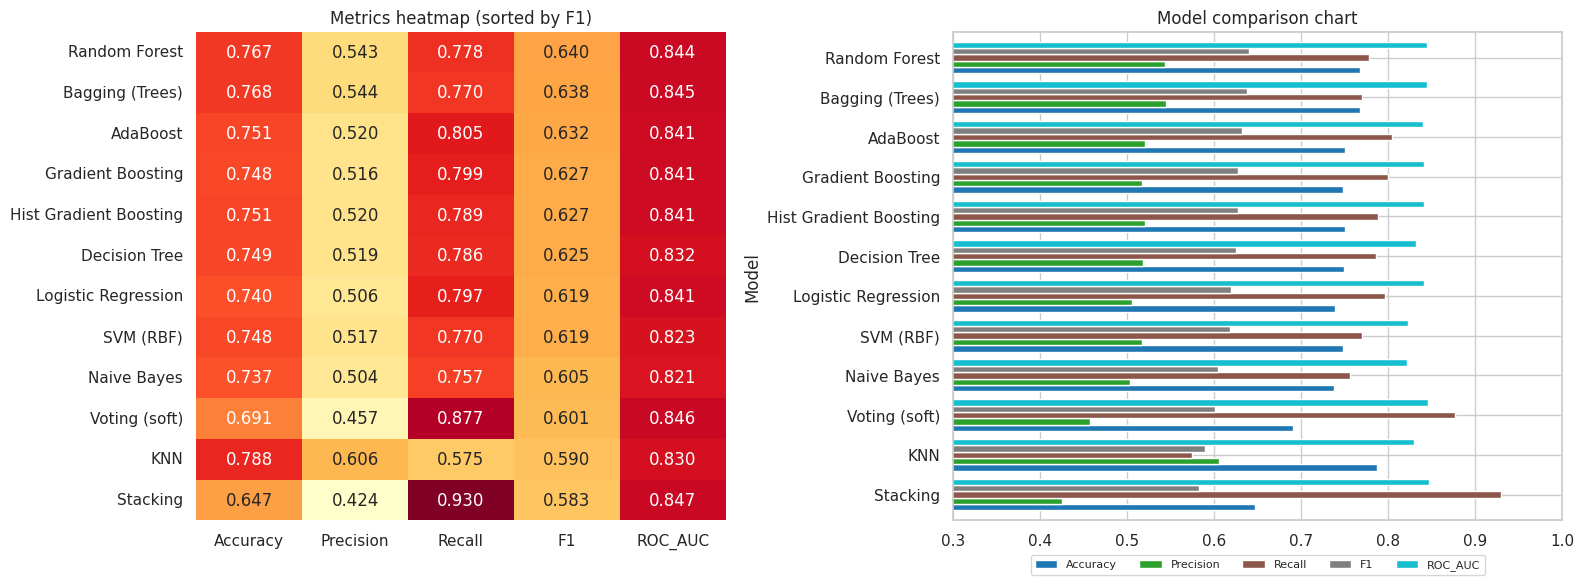

In [43]:
metrics = ['Accuracy', 'Precision', 'Recall', 'F1', 'ROC_AUC']
fig, ax = plt.subplots(1, 2, figsize=(16, 6), gridspec_kw={'width_ratios': [1, 1.15]})
sns.heatmap(table.set_index('Model')[metrics], annot=True, fmt='.3f', cmap='YlOrRd', ax=ax[0], cbar=False)
ax[0].set_title('Metrics heatmap (sorted by F1)'); ax[0].set_ylabel('')
tp = table.set_index('Model')[metrics].iloc[::-1]
tp.plot.barh(ax=ax[1], width=0.8, colormap='tab10')
ax[1].set_title('Model comparison chart'); ax[1].set_xlim(0.3, 1.0); ax[1].legend(loc='upper center', bbox_to_anchor=(0.5, -0.06), ncol=5, fontsize=8)
plt.tight_layout(); plt.show()

**What it shows:** all 12 models on 5 metrics, sorted by F1 (heatmap and grouped bars).

**Key findings:**
- **Random Forest ranks first by F1 (0.640)**, followed closely by Bagging (0.638), AdaBoost (0.632), Stacking (0.628) and the other boosters (0.627). KNN is last (0.590) and Naive Bayes second to last (0.605).
- **Accuracy is misleading:** KNN has the highest accuracy (0.788) and the highest precision (0.606) but the **lowest recall (0.575)** — it misses about 4 in 10 churners because it has no class weighting. A "never churn" model would score 0.735 accuracy.
- All other models catch **76–83% of churners** (recall) with precision around 0.49–0.54, i.e. roughly one in two retention offers goes to a customer who would really leave.
- ROC-AUC is tightly packed between 0.821 and 0.847, with Stacking highest (0.847), then Voting, Bagging and Random Forest (≈ 0.844–0.845).
- The train accuracy (0.75–0.81) is close to test accuracy (0.74–0.79) for every model, so **none of the models is badly overfitted**.

**Best model:** Random Forest by F1 (ties broken by AUC). The next sections look at its errors in detail.

### Confusion matrices (all models)

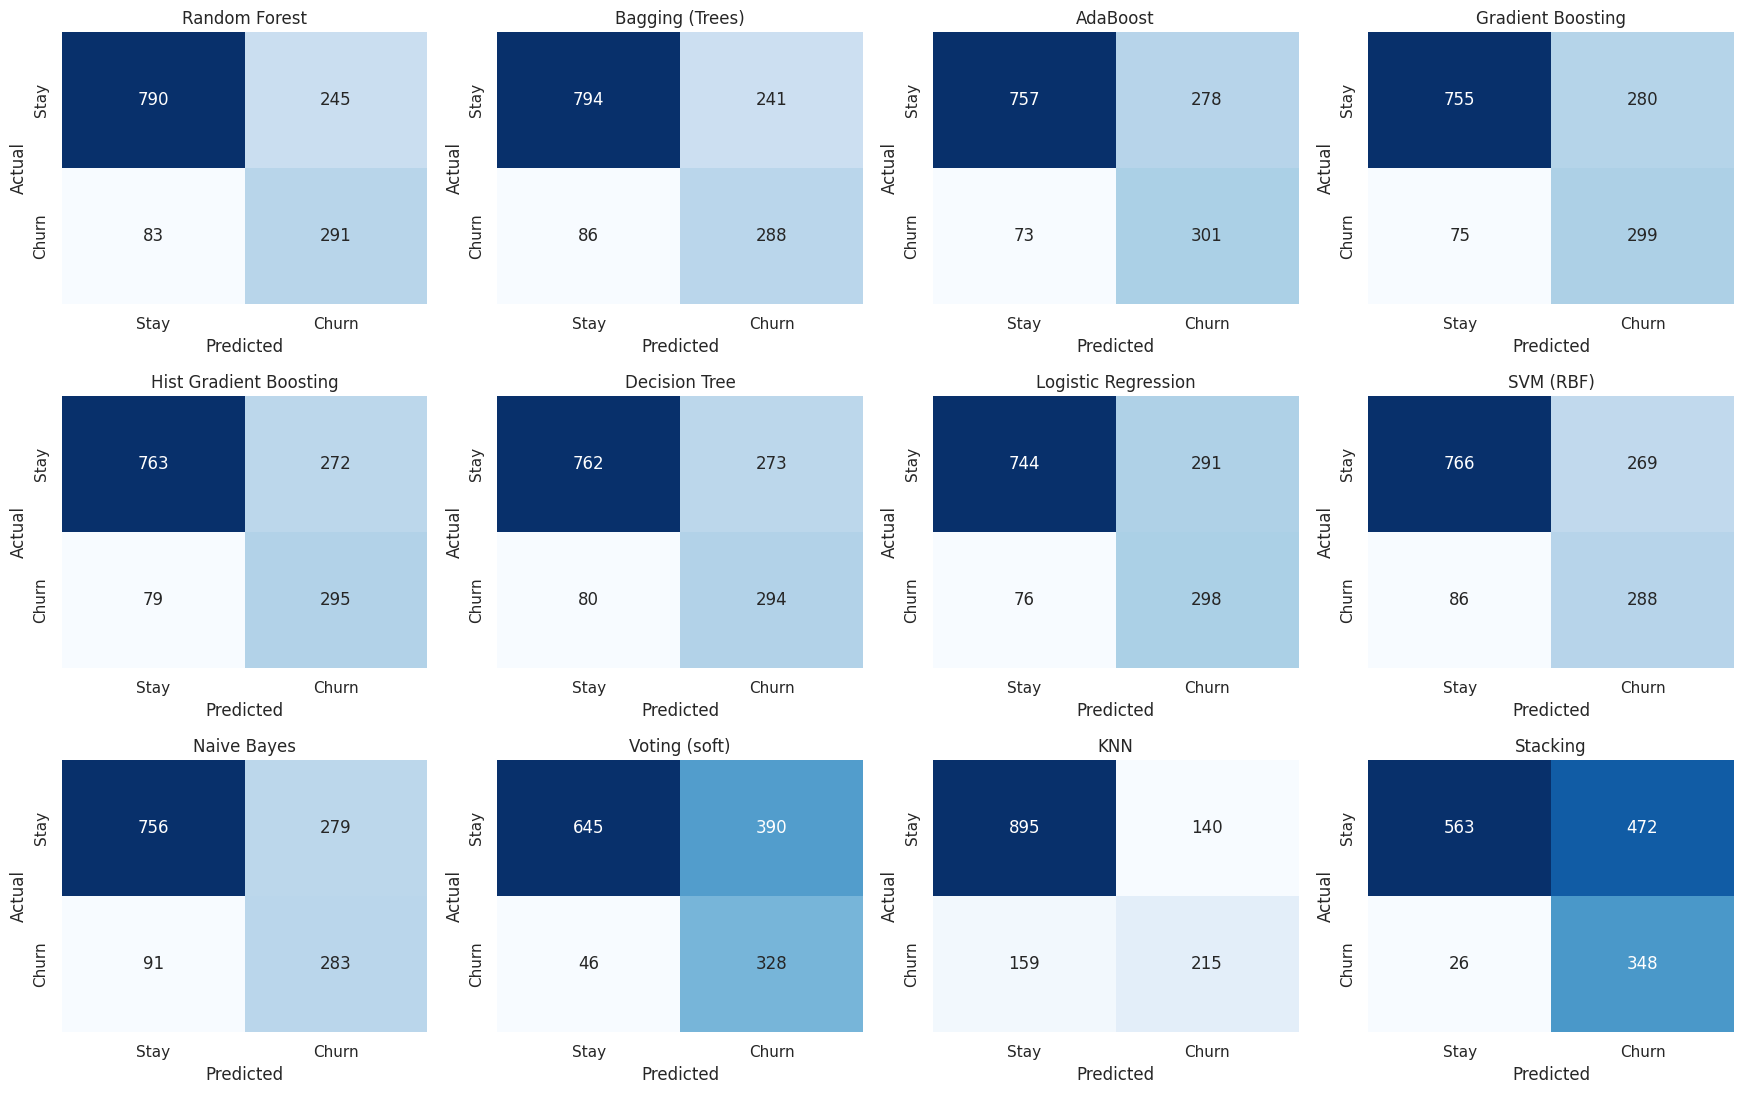

In [44]:
names = list(table['Model'])
ncols = 4; nrows = int(np.ceil(len(names) / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(4.4 * ncols, 3.7 * nrows))
axes = axes.reshape(-1)
for ax, n in zip(axes, names):
    cm = confusion_matrix(yte, fitted[n]['pred'])
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False, ax=ax, xticklabels=['Stay', 'Churn'], yticklabels=['Stay', 'Churn'])
    ax.set_title(n); ax.set_xlabel('Predicted'); ax.set_ylabel('Actual')
for ax in axes[len(names):]: ax.set_visible(False)
plt.tight_layout(); plt.show()

**What it shows:** for each model, true negatives (top-left), false positives (top-right), false negatives (bottom-left) and true positives (bottom-right) on the 1,409 test customers (374 actual churners).

**Why it matters:** models with many false negatives miss churners (lost revenue); models with many false positives waste retention offers. The class-weighted models accept more false positives to catch many more churners; KNN (no class weighting) is the opposite extreme, with the fewest false positives but also the most missed churners, while Voting and Stacking catch the most churners at the cost of the most false alarms.

### Classification report for the best model

In [45]:
print(f'Best model: {best_name}\n')
print(classification_report(yte, fitted[best_name]['pred'], target_names=['Stayed (0)', 'Churned (1)'], digits=3))
cm = confusion_matrix(yte, fitted[best_name]['pred'])
print('Confusion matrix [[TN FP] [FN TP]]:\n', cm)

Best model: Random Forest

              precision    recall  f1-score   support

  Stayed (0)      0.905     0.763     0.828      1035
 Churned (1)      0.543     0.778     0.640       374

    accuracy                          0.767      1409
   macro avg      0.724     0.771     0.734      1409
weighted avg      0.809     0.767     0.778      1409

Confusion matrix [[TN FP] [FN TP]]:
 [[790 245]
 [ 83 291]]


### ROC curves

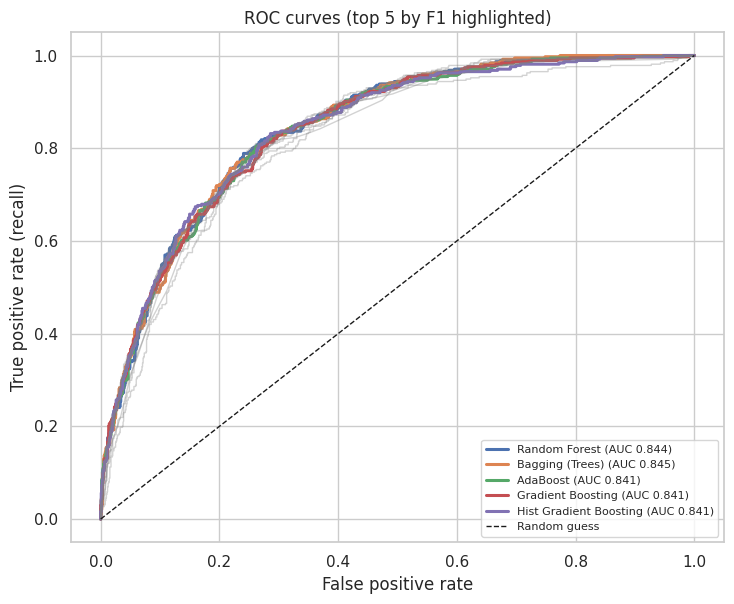

In [46]:
fig, ax = plt.subplots(figsize=(7.5, 6.2))
top5 = list(table['Model'][:5])
for n in names:
    fpr, tpr, _ = roc_curve(yte, fitted[n]['proba'])
    if n in top5:
        ax.plot(fpr, tpr, lw=2.2, label=f"{n} (AUC {roc_auc_score(yte, fitted[n]['proba']):.3f})")
    else:
        ax.plot(fpr, tpr, lw=1, alpha=0.35, color='grey')
ax.plot([0, 1], [0, 1], 'k--', lw=1, label='Random guess')
ax.set_xlabel('False positive rate'); ax.set_ylabel('True positive rate (recall)')
ax.set_title('ROC curves (top 5 by F1 highlighted)'); ax.legend(loc='lower right', fontsize=8)
plt.tight_layout(); plt.show()

**What it shows:** the trade-off between catching churners (y-axis) and falsely flagging loyal customers (x-axis) across all thresholds. The closer to the top-left corner, the better; the diagonal is random guessing.

**Key findings:** all models are far above the diagonal (AUC 0.82–0.85), and the top models' curves almost overlap, confirming that they rank customers by risk in nearly the same way. The AUC of 0.84 means that a randomly chosen churner gets a higher risk score than a randomly chosen loyal customer about 84% of the time.

### Which features drive the prediction? (Logistic Regression coefficients)

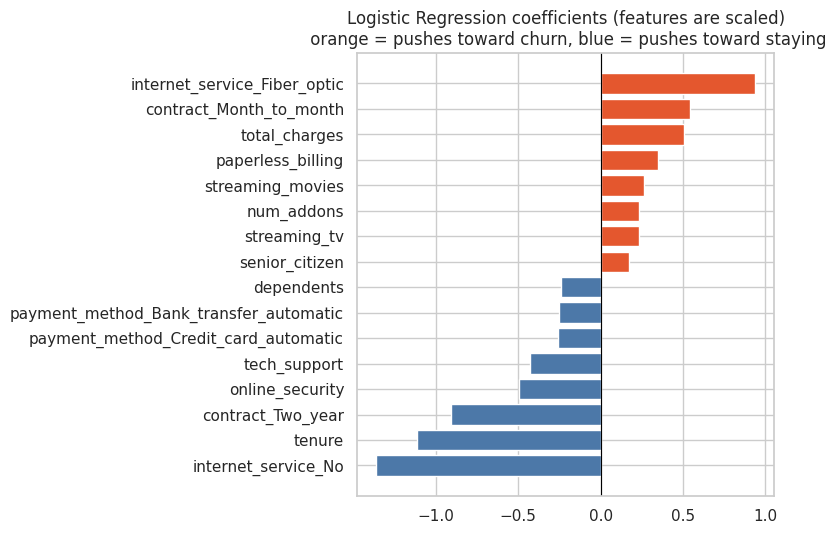

In [47]:
lr = fitted['Logistic Regression']['model']
coef = pd.Series(lr.coef_[0], index=Xtr.columns).sort_values()
show = pd.concat([coef.head(8), coef.tail(8)])
fig, ax = plt.subplots(figsize=(8, 5.5))
ax.barh(show.index, show.values, color=['#4C78A8' if v < 0 else '#E4572E' for v in show.values])
ax.axvline(0, color='black', lw=0.8)
ax.set_title('Logistic Regression coefficients (features are scaled)\n orange = pushes toward churn, blue = pushes toward staying')
plt.tight_layout(); plt.show()

**What it shows:** the direction and strength with which each (scaled) feature pushes the Logistic Regression prediction toward churn (orange) or toward staying (blue).

**Key findings:** `tenure` and `contract_Two_year` are the strongest protective features, while month-to-month contracts, fiber-optic internet and electronic-check payment push toward churn. This matches the EDA and gives the business directly actionable levers: longer contracts, automatic payment and security/support add-ons. Note that coefficients of correlated features such as `tenure` and `total_charges` should be read with care.

### Save the best model for the Streamlit app
The bundle stores everything needed to reproduce the exact same preprocessing at prediction time: the model, the scaler, the list of scaled columns, and the selected feature order.

In [51]:
bundle = {
    'model': fitted[best_name]['model'],
    'model_name': best_name,
    'scaler': scaler,
    'scale_cols': scale_cols,
    'all_features': list(X_train.columns),     # column order after engineer_features()
    'selected_features': selected,             # columns the model was trained on
    'metrics': table.set_index('Model').loc[best_name, ['Accuracy', 'Precision', 'Recall', 'F1', 'ROC_AUC']].round(4).to_dict(),
}
joblib.dump(bundle, 'churn_model.joblib')

# Sanity check: reload and reproduce the test-set predictions exactly
chk = joblib.load('churn_model.joblib')
p = chk['model'].predict_proba(X_test_s[chk['selected_features']])[:, 1]
print('Saved churn_model.joblib  | model:', chk['model_name'])
print('Reloaded model reproduces test predictions:', bool(np.allclose(p, fitted[best_name]['proba'])))

Saved churn_model.joblib  | model: Random Forest
Reloaded model reproduces test predictions: True


---
# Part 9 — Conclusion

**Most important preprocessing steps**

- Found and fixed the **hidden missing values**: `total_charges` was stored as text and 11 blanks (all brand-new customers with tenure 0) were converted and filled with 0, which is exact rather than an estimate.
- Merged the redundant `No internet service` / `No phone service` labels into `No`, dropped the ID column, and checked duplicates (none) and outliers (none).
- Label-encoded binary columns and the target, one-hot encoded `internet_service`, `contract` and `payment_method`, and created four features (`num_addons`, `avg_monthly_charge`, `charge_change`, `has_family`); `charge_change` turned out to be one of the most informative features despite near-zero linear correlation.
- Avoided leakage: stratified 80/20 split with `random_state=42`, scaler and feature selection fitted on the training set only (3 useless features dropped, 27 kept), and balanced class weights to handle the 26.5% churn rate.

**Key EDA insights**

1. Only 26.5% of customers churn, so recall, F1 and ROC-AUC matter more than accuracy.
2. Contract type is the strongest driver: month-to-month customers churn at 42.7% vs 2.8% for two-year contracts and are 88.6% of all churners.
3. Churn falls with tenure (47.4% in year one, 9.5% after four years); 55.5% of churners leave within 12 months.
4. Fiber-optic (41.9%) and electronic-check (45.3%) customers are high risk; month-to-month + fiber + electronic check reaches 60.4%.
5. Online security and tech support cut churn from about 42% to about 15% among internet customers; gender has no effect.

**Best-performing model: Random Forest**
On the 1,409-customer test set it reached **F1 = 0.640, recall = 0.778, precision = 0.543, accuracy = 0.767 and ROC-AUC = 0.844**. It correctly flags 291 of the 374 churners and raises 245 false alarms.

**Why this model was selected**

- It has the highest F1 of all 12 models, with a good balance between catching churners (recall) and not wasting offers (precision); it trains in about a second.
- It is not overfitted (train accuracy 0.797 vs test 0.767) and offers feature importances that match the EDA, which makes it easy to explain to business teams.
- The ensembles did **not clearly beat it**: Bagging is essentially tied (F1 0.638), boosting models are slightly lower in F1 (0.627–0.632), Voting has the highest recall (0.834) and Stacking the highest AUC (0.847), but Stacking needs about 16× the training time for no F1 gain. With only 374 churners in the test set, gaps of about 0.01 are within noise, so these models should be considered about equal; Random Forest wins on simplicity and speed. If the business cares more about catching every churner than about wasted offers, Voting or Stacking (recall > 0.82) would be reasonable alternatives.
- KNN has the best accuracy (0.788) but misses 42% of churners, which shows why accuracy was not used to choose the model.

**Possible future improvements**

- Tune hyperparameters with cross-validated search and compare models with k-fold cross-validation instead of a single split to get more reliable rankings.
- Choose the decision threshold from the real cost of a lost customer versus a retention offer, instead of the default 0.5.
- Try SMOTE or other resampling, and gradient-boosting libraries such as XGBoost / LightGBM / CatBoost.
- Add richer data (usage, support calls, complaints, competitor offers, price changes over time) and explain individual predictions with SHAP values.
- Calibrate probabilities, monitor the model for drift, and run A/B tests of retention offers aimed at the high-risk segments found in the EDA (new month-to-month fiber customers paying by electronic check).
